# Class 05 — Uber Pickups in New York City (September 2014): Spatial Clustering and Demand Forecasting

**Data:** `uber-data.csv` (Uber pickup records, New York City, September 2014)

> Required packages: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `statsmodels`.

## 1. Introduction

**Purpose.** This assignment analyses where and when Uber pickups occurred in New York City during September 2014. It combines (i) geographic clustering of pickup locations, (ii) the temporal profile of each cluster, and (iii) an hourly demand forecast for the whole city.

**Dataset.** Each row is one pickup with four variables:

| Variable | Meaning |
|---|---|
| `Date/Time` | Pickup timestamp (month/day/year hour:minute:second) |
| `Lat`, `Lon` | Pickup latitude and longitude (decimal degrees) |
| `Base` | Code of the TLC-licensed dispatching base that handled the pickup |

**Analytical objectives.**
1. Clean and validate the data, reporting every row removed and why.
2. Describe the spatial and temporal structure of pickups (EDA).
3. Convert coordinates to kilometres and find geographic clusters with K-Means (MiniBatchKMeans for the full data), choosing *k* with four internal criteria.
4. Compare with a density-based method (DBSCAN with the haversine metric).
5. Study cluster activity by hour and by date.
6. Forecast hourly pickups with a chronological train/test split and forecast the next 24 hours.

**Methodology in brief.** Pickup records are cleaned, projected to a local planar kilometre grid, clustered, and profiled in time. For forecasting, the records are aggregated into an hourly series; models are fitted on the earlier part of the series only and scored on the final 7 days, which were never used for fitting.

## 2. Libraries and dataset loading

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.cluster import KMeans, MiniBatchKMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning as SMConvergenceWarning

# Known, harmless warnings are filtered specifically (not all warnings):
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

def fmt_table(frame, formats):
    # return a copy of `frame` with selected columns formatted as strings (no optional dependencies needed)
    out = frame.copy()
    for col, f in formats.items():
        out[col] = out[col].map(lambda v, f=f: f.format(v))
    return out

DATA_PATH = "uber-data.csv"
if not os.path.exists(DATA_PATH):                      # fall back to the upload folder if present
    alt = "/mnt/user-data/uploads/uber-data.csv"
    if os.path.exists(alt):
        DATA_PATH = alt
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError("uber-data.csv not found. Put it next to this notebook or edit DATA_PATH.")

raw = pd.read_csv(DATA_PATH)

REQUIRED_COLUMNS = ["Date/Time", "Lat", "Lon", "Base"]
missing_cols = [c for c in REQUIRED_COLUMNS if c not in raw.columns]
if missing_cols:
    raise KeyError(f"Dataset is missing required columns: {missing_cols}. Found: {list(raw.columns)}")

print("Dataset file      :", DATA_PATH)
print("Dimensions        :", raw.shape[0], "rows x", raw.shape[1], "columns")
print("\nColumn names and data types:")
print(raw.dtypes.to_string())
print("\nFirst five records:")
display(raw.head())
print("Basic information:")
raw.info(memory_usage="deep")

Dataset file      : uber-data.csv
Dimensions        : 1028136 rows x 4 columns

Column names and data types:
Date/Time        str
Lat          float64
Lon          float64
Base             str

First five records:


,Date/Time,Lat,Lon,Base
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512
3,9/1/2014 0:06:00,40.7450,-73.9889,B02512
4,9/1/2014 0:11:00,40.8145,-73.9444,B02512


Basic information:
<class 'pandas.DataFrame'>
RangeIndex: 1028136 entries, 0 to 1028135
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype  
---  ------     --------------    -----  
 0   Date/Time  1028136 non-null  str    
 1   Lat        1028136 non-null  float64
 2   Lon        1028136 non-null  float64
 3   Base       1028136 non-null  str    
dtypes: float64(2), str(2)
memory usage: 134.8 MB


## 3. Data cleaning and preprocessing

Every step below prints the number of records **before and after**, and the reason for the step.

* **Timestamps.** The timestamps contain seconds (e.g. `9/1/2014 0:01:00`), so the format string includes `%S`. If any rows fail the strict format, a flexible parser (`format="mixed"`) is tried on those rows only.
* **Missing values and invalid coordinates.** Rows with missing time or location cannot be used. Latitude must lie in [-90, 90] and longitude in [-180, 180].
* **Duplicates.** Rows identical in all four fields are removed, as the assignment requires. *Caveat:* timestamps have only one-minute resolution and coordinates are rounded to four decimals (about 10 m), so some "duplicates" could be genuinely separate pickups at the same spot in the same minute. Removal therefore slightly *understates* demand; the size of this effect is reported and discussed in the limitations.
* **Geographic filter.** A deliberately generous bounding box around the New York metropolitan area (latitude 40.4–41.2, longitude -74.5 to -73.4) is applied. It is only a sanity filter against clearly wrong coordinates: tighter boxes would also remove plausible airport and suburban pickups. K-Means centroids are sensitive to very distant points, which is why such points are removed.

In [2]:
cleaning_log = []          # (step, rows_before, rows_after, removed)

def log_step(step, before, after):
    cleaning_log.append((step, before, after, before - after))
    print(f"{step:<42s} before: {before:>9,d}  after: {after:>9,d}  removed: {before - after:>7,d}")

df = raw.copy()
n_raw = len(df)

# --- 3.1 Timestamp conversion (strict format with seconds, then flexible fallback) ---
ts = pd.to_datetime(df["Date/Time"], format="%m/%d/%Y %H:%M:%S", errors="coerce")
n_strict_fail = int(ts.isna().sum())
if n_strict_fail:
    ts_fallback = pd.to_datetime(df.loc[ts.isna(), "Date/Time"], format="mixed", errors="coerce")
    ts.loc[ts.isna()] = ts_fallback
df["Date/Time"] = ts
print(f"Strict-format parse failures: {n_strict_fail:,d}; unparseable after fallback: {int(df['Date/Time'].isna().sum()):,d}")
print(f"Rows whose timestamp has non-zero seconds: {int((df['Date/Time'].dt.second != 0).sum()):,d}")

# --- 3.2 Missing values ---
print("\nMissing values per column (before cleaning):")
print(df.isna().sum().to_string())
before = len(df)
df = df.dropna(subset=REQUIRED_COLUMNS)
log_step("Drop rows with missing values/timestamps", before, len(df))

# --- 3.3 Invalid coordinates ---
before = len(df)
valid_coord = df["Lat"].between(-90, 90) & df["Lon"].between(-180, 180)
df = df[valid_coord]
log_step("Drop impossible coordinates", before, len(df))

# --- 3.4 Duplicates ---
before = len(df)
df = df.drop_duplicates(subset=REQUIRED_COLUMNS)
log_step("Drop exact duplicates (all 4 fields)", before, len(df))
n_duplicates_removed = before - len(df)

# --- 3.5 Geographic bounding box ---
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 40.4, 41.2, -74.5, -73.4
before = len(df)
in_box = df["Lat"].between(LAT_MIN, LAT_MAX) & df["Lon"].between(LON_MIN, LON_MAX)
df = df[in_box].copy()
log_step("Drop points outside NYC-area bounding box", before, len(df))
n_outside_box = before - len(df)

# --- 3.6 Feature engineering ---
df = df.sort_values("Date/Time").reset_index(drop=True)
df["Date"] = df["Date/Time"].dt.normalize()
df["Hour"] = df["Date/Time"].dt.hour
df["Weekday"] = df["Date/Time"].dt.weekday            # 0 = Monday
df["Weekday_name"] = df["Date/Time"].dt.day_name()
df["Month"] = df["Date/Time"].dt.month
df["IsWeekend"] = (df["Weekday"] >= 5).astype(int)
df["Base"] = df["Base"].astype("category")

cleaning_summary = pd.DataFrame(cleaning_log, columns=["Step", "Rows before", "Rows after", "Removed"])
display(cleaning_summary)

n_clean = len(df)
date_start, date_end = df["Date/Time"].min(), df["Date/Time"].max()
print(f"\nFinal cleaned dimensions : {df.shape[0]:,d} rows x {df.shape[1]} columns")
print(f"Retained share of raw data: {100 * n_clean / n_raw:.2f}%")
print(f"Date range               : {date_start}  ->  {date_end}")
print(f"Distinct calendar days   : {df['Date'].nunique()}")
display(df.head())

Strict-format parse failures: 0; unparseable after fallback: 0
Rows whose timestamp has non-zero seconds: 0

Missing values per column (before cleaning):
Date/Time    0
Lat          0
Lon          0
Base         0
Drop rows with missing values/timestamps   before: 1,028,136  after: 1,028,136  removed:       0
Drop impossible coordinates                before: 1,028,136  after: 1,028,136  removed:       0
Drop exact duplicates (all 4 fields)       before: 1,028,136  after: 1,004,099  removed:  24,037
Drop points outside NYC-area bounding box  before: 1,004,099  after: 1,003,491  removed:     608


,Step,Rows before,Rows after,Removed
0,Drop rows with missing values/timestamps,1028136,1028136,0
1,Drop impossible coordinates,1028136,1028136,0
2,Drop exact duplicates (all 4 fields),1028136,1004099,24037
3,Drop points outside NYC-area bounding box,1004099,1003491,608



Final cleaned dimensions : 1,003,491 rows x 10 columns
Retained share of raw data: 97.60%
Date range               : 2014-09-01 00:00:00  ->  2014-09-30 22:59:00
Distinct calendar days   : 30


,Date/Time,Lat,Lon,Base,Date,Hour,Weekday,Weekday_name,Month,IsWeekend
0,2014-09-01,40.7283,-74.0055,B02682,2014-09-01,0,0,Monday,9,0
1,2014-09-01,40.8259,-73.9451,B02598,2014-09-01,0,0,Monday,9,0
2,2014-09-01,40.7222,-73.9881,B02598,2014-09-01,0,0,Monday,9,0
3,2014-09-01,40.7206,-73.9970,B02598,2014-09-01,0,0,Monday,9,0
4,2014-09-01,40.7267,-73.9409,B02598,2014-09-01,0,0,Monday,9,0


## 4. Exploratory data analysis

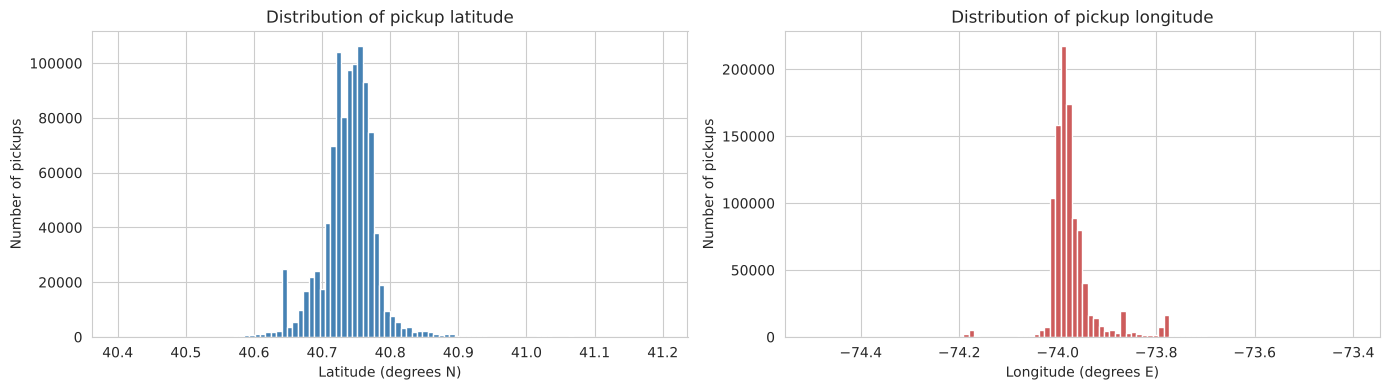

,Lat,Lon
0.0100,40.6399,-74.1033
0.0500,40.6704,-74.0103
0.2500,40.7204,-73.9962
0.5000,40.7418,-73.9831
0.7500,40.7612,-73.9629
0.9500,40.7886,-73.8655
0.9900,40.8531,-73.7769


**Interpretation.** The median pickup is at latitude 40.7418, longitude -73.9831. The 5%-95% range is 40.670 to 40.789 in latitude and -74.010 to -73.865 in longitude. The most frequent 0.01-degree bins are latitude 40.76 and longitude -73.99. 74.7% of pickups fall inside the rectangle latitude 40.70-40.80, longitude -74.02 to -73.95, so pickups are strongly concentrated in a compact central area with a long tail of more distant points.

In [3]:
# --- 4.1 Latitude and longitude distributions ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df["Lat"], bins=100, color="steelblue")
axes[0].set_title("Distribution of pickup latitude"); axes[0].set_xlabel("Latitude (degrees N)"); axes[0].set_ylabel("Number of pickups")
axes[1].hist(df["Lon"], bins=100, color="indianred")
axes[1].set_title("Distribution of pickup longitude"); axes[1].set_xlabel("Longitude (degrees E)"); axes[1].set_ylabel("Number of pickups")
plt.tight_layout(); plt.show()

q = df[["Lat", "Lon"]].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
display(q)
lat_mode_bin = df["Lat"].round(2).mode().iloc[0]
lon_mode_bin = df["Lon"].round(2).mode().iloc[0]
share_core = ((df["Lat"].between(40.70, 40.80)) & (df["Lon"].between(-74.02, -73.95))).mean()
display(Markdown(
    f"**Interpretation.** The median pickup is at latitude {df['Lat'].median():.4f}, longitude {df['Lon'].median():.4f}. "
    f"The 5%-95% range is {q.loc[0.05,'Lat']:.3f} to {q.loc[0.95,'Lat']:.3f} in latitude and {q.loc[0.05,'Lon']:.3f} to {q.loc[0.95,'Lon']:.3f} in longitude. "
    f"The most frequent 0.01-degree bins are latitude {lat_mode_bin:.2f} and longitude {lon_mode_bin:.2f}. "
    f"{100*share_core:.1f}% of pickups fall inside the rectangle latitude 40.70-40.80, longitude -74.02 to -73.95, "
    f"so pickups are strongly concentrated in a compact central area with a long tail of more distant points."))

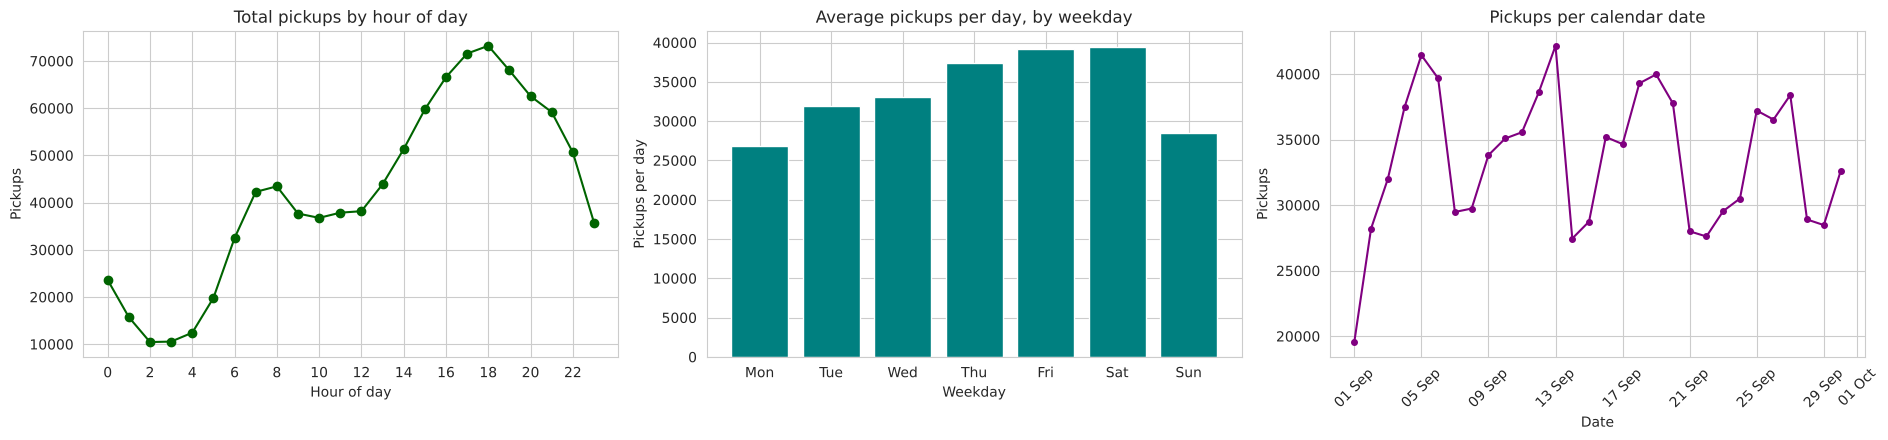

,Total pickups,Days in data,Average per day
Weekday_name,,,
Monday,134112,5,"26,822"
Tuesday,159319,5,"31,864"
Wednesday,132222,4,"33,056"
Thursday,149532,4,"37,383"
Friday,156518,4,"39,130"
Saturday,157965,4,"39,491"
Sunday,113823,4,"28,456"


**Interpretation.** Pickups peak at 18:00 (73,208 pickups over the month) and are lowest at 02:00 (10,444). Weekday totals partly reflect how many of each weekday occur in the month, so the per-day average is more informative: the busiest weekday on average is Saturday (39,491 per day) and the quietest is Monday (26,822 per day). The busiest date is 13 Sep 2014 (42,148 pickups) and the quietest is 01 Sep 2014 (19,552). No causal explanation (events, weather, holidays) is claimed because none is in the data.

In [4]:
# --- 4.2 Trips by hour, weekday and date ---
hour_counts = df.groupby("Hour").size()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = df.groupby("Weekday_name").size().reindex(weekday_order)
# the number of each weekday present in the data, so totals are not mistaken for demand per day
days_per_weekday = df.drop_duplicates("Date").groupby("Weekday_name").size().reindex(weekday_order)
weekday_avg = weekday_counts / days_per_weekday
date_counts = df.groupby("Date").size()

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
axes[0].plot(hour_counts.index, hour_counts.values, marker="o", color="darkgreen")
axes[0].set_title("Total pickups by hour of day"); axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Pickups"); axes[0].set_xticks(range(0, 24, 2))
axes[1].bar(range(7), weekday_avg.values, color="teal")
axes[1].set_xticks(range(7)); axes[1].set_xticklabels([d[:3] for d in weekday_order])
axes[1].set_title("Average pickups per day, by weekday"); axes[1].set_xlabel("Weekday"); axes[1].set_ylabel("Pickups per day")
axes[2].plot(date_counts.index, date_counts.values, marker="o", ms=4, color="purple")
axes[2].set_title("Pickups per calendar date"); axes[2].set_xlabel("Date"); axes[2].set_ylabel("Pickups")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

weekday_table = pd.DataFrame({"Total pickups": weekday_counts, "Days in data": days_per_weekday, "Average per day": weekday_avg.round(0)})
display(fmt_table(weekday_table, {"Average per day": "{:,.0f}"}))

peak_hour = int(hour_counts.idxmax()); trough_hour = int(hour_counts.idxmin())
top_date, low_date = date_counts.idxmax(), date_counts.idxmin()
display(Markdown(
    f"**Interpretation.** Pickups peak at {peak_hour:02d}:00 ({hour_counts.max():,d} pickups over the month) and are lowest at {trough_hour:02d}:00 ({hour_counts.min():,d}). "
    f"Weekday totals partly reflect how many of each weekday occur in the month, so the per-day average is more informative: "
    f"the busiest weekday on average is {weekday_avg.idxmax()} ({weekday_avg.max():,.0f} per day) and the quietest is {weekday_avg.idxmin()} ({weekday_avg.min():,.0f} per day). "
    f"The busiest date is {top_date:%d %b %Y} ({date_counts.max():,d} pickups) and the quietest is {low_date:%d %b %Y} ({date_counts.min():,d}). "
    f"No causal explanation (events, weather, holidays) is claimed because none is in the data."))

,Pickups,Share (%)
Base,,
B02617,366476,36.5200
B02598,238041,23.7200
B02682,194206,19.3500
B02764,171204,17.0600
B02512,33564,3.3400


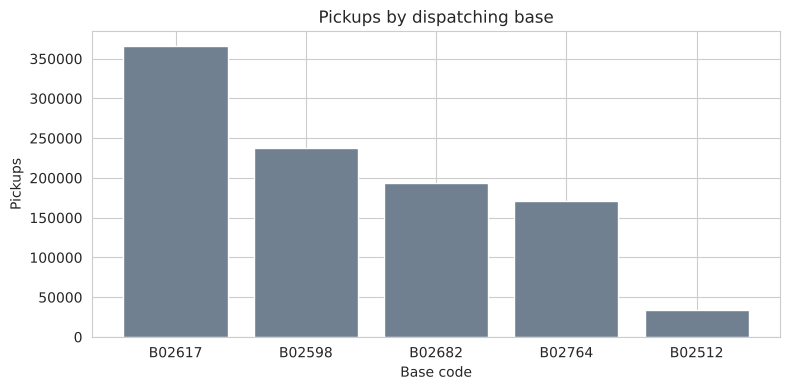

**Interpretation.** The data contain 5 bases. The largest, B02617, accounts for 36.5% of pickups; the smallest, B02512, accounts for 3.3%. The base is an administrative dispatching code and is not used as a geographic variable in this analysis.

In [5]:
# --- 4.3 Distribution of Uber bases ---
base_counts = df["Base"].value_counts()
base_table = pd.DataFrame({"Pickups": base_counts, "Share (%)": (100 * base_counts / base_counts.sum()).round(2)})
display(base_table)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(base_counts.index.astype(str), base_counts.values, color="slategray")
ax.set_title("Pickups by dispatching base"); ax.set_xlabel("Base code"); ax.set_ylabel("Pickups")
plt.tight_layout(); plt.show()
display(Markdown(
    f"**Interpretation.** The data contain {df['Base'].nunique()} bases. The largest, {base_counts.index[0]}, accounts for {100*base_counts.iloc[0]/base_counts.sum():.1f}% of pickups; "
    f"the smallest, {base_counts.index[-1]}, accounts for {100*base_counts.iloc[-1]/base_counts.sum():.1f}%. "
    f"The base is an administrative dispatching code and is not used as a geographic variable in this analysis."))

## 5. Geographic preprocessing

**Why not cluster raw degrees?** K-Means and DBSCAN with a Euclidean metric measure straight-line distance in the feature space. One degree of latitude is about 111 km everywhere, but one degree of longitude shrinks with the cosine of the latitude (about 84 km at New York's latitude). Euclidean distance on raw degrees would therefore stretch east-west distances relative to north-south distances.

**Transformation used (local equirectangular projection).** With reference point (φ₀, λ₀) = the mean pickup latitude and longitude and Earth radius R = 6371.0088 km:

$$x = R\,\cos\varphi_0\,(\lambda-\lambda_0), \qquad y = R\,(\varphi-\varphi_0) \qquad (\text{angles in radians})$$

The inverse is $\lambda = \lambda_0 + x/(R\cos\varphi_0)$ and $\varphi = \varphi_0 + y/R$. Over a region of a few tens of kilometres this approximation is accurate to well under 1% for distances, which is adequate for this purpose.

**Scaling.** No additional standardisation is applied. Both coordinates are already in kilometres, so Euclidean distance in the feature space equals ground distance. Standardising each axis separately would distort true distances (the east-west spread is smaller than the north-south spread) and would make cluster sizes harder to interpret.

In [6]:
EARTH_RADIUS_KM = 6371.0088
lat0_deg, lon0_deg = df["Lat"].mean(), df["Lon"].mean()
lat0_rad = np.radians(lat0_deg)

def to_km(lat_deg, lon_deg):
    # (lat, lon) in degrees -> (x_km, y_km) relative to the reference point
    x = EARTH_RADIUS_KM * np.cos(lat0_rad) * np.radians(np.asarray(lon_deg) - lon0_deg)
    y = EARTH_RADIUS_KM * np.radians(np.asarray(lat_deg) - lat0_deg)
    return x, y

def to_degrees(x_km, y_km):
    # inverse transformation: (x_km, y_km) -> (lat, lon) in degrees
    lat = lat0_deg + np.degrees(np.asarray(y_km) / EARTH_RADIUS_KM)
    lon = lon0_deg + np.degrees(np.asarray(x_km) / (EARTH_RADIUS_KM * np.cos(lat0_rad)))
    return lat, lon

df["x_km"], df["y_km"] = to_km(df["Lat"].values, df["Lon"].values)
X = df[["x_km", "y_km"]].to_numpy(dtype=np.float64)

# Consistency check 1: inverse(forward(.)) reproduces the original coordinates
lat_back, lon_back = to_degrees(df["x_km"].values, df["y_km"].values)
roundtrip_err_deg = max(np.abs(lat_back - df["Lat"].values).max(), np.abs(lon_back - df["Lon"].values).max())
# Consistency check 2: planar distance vs great-circle (haversine) distance for random pairs
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))
rs_pairs = np.random.RandomState(SEED)
ia, ib = rs_pairs.randint(0, len(df), 50000), rs_pairs.randint(0, len(df), 50000)
d_planar = np.hypot(X[ia, 0] - X[ib, 0], X[ia, 1] - X[ib, 1])
d_haver = haversine_km(df["Lat"].values[ia], df["Lon"].values[ia], df["Lat"].values[ib], df["Lon"].values[ib])
keep = d_haver > 1.0
rel_err = np.abs(d_planar[keep] - d_haver[keep]) / d_haver[keep]

print(f"Reference point        : lat0 = {lat0_deg:.5f}, lon0 = {lon0_deg:.5f}")
print(f"Km per degree latitude : {np.radians(1) * EARTH_RADIUS_KM:.2f}")
print(f"Km per degree longitude: {np.radians(1) * EARTH_RADIUS_KM * np.cos(lat0_rad):.2f}  (at the reference latitude)")
print(f"Feature matrix X       : shape {X.shape} (columns: x_km, y_km), no further scaling")
print(f"x_km range             : {X[:,0].min():.1f} to {X[:,0].max():.1f} km;  y_km range: {X[:,1].min():.1f} to {X[:,1].max():.1f} km")
print(f"Max round-trip error   : {roundtrip_err_deg:.2e} degrees")
print(f"Planar vs haversine distance (random pairs >1 km): median relative error {100*np.median(rel_err):.3f}%, 99th percentile {100*np.percentile(rel_err, 99):.3f}%")
assert roundtrip_err_deg < 1e-9, "Inverse transformation is not consistent with the forward transformation."

Reference point        : lat0 = 40.73921, lon0 = -73.97204
Km per degree latitude : 111.20
Km per degree longitude: 84.25  (at the reference latitude)
Feature matrix X       : shape (1003491, 2) (columns: x_km, y_km), no further scaling
x_km range             : -44.4 to 48.2 km;  y_km range: -37.5 to 50.9 km
Max round-trip error   : 0.00e+00 degrees
Planar vs haversine distance (random pairs >1 km): median relative error 0.005%, 99th percentile 0.082%


## 6. Geographic clustering

**Algorithm: K-Means (primary), fitted with MiniBatchKMeans on the full data.**

* *Why K-Means?* The aim is to partition pickups into a small number of compact geographic zones with interpretable centres (centroids). K-Means gives exactly that and is fast.
* *Assumptions.* Clusters are roughly convex and similar in spatial extent; every point is assigned to one cluster; distance is Euclidean (this is why Section 5 projects coordinates to kilometres); *k* must be specified in advance.
* *Advantages.* Simple, scalable, deterministic given a seed, centroids are easy to interpret.
* *Limitations.* Sensitive to outliers and to initialisation, tends to split dense areas rather than isolate sparse ones, cannot find irregular or elongated shapes, and does not label noise.
* *Training.* To choose *k* (Section 7), exact `KMeans` with 10 random restarts is fitted on a fixed random sample of 50,000 pickups (reproducible via the seed), because computing silhouette and related indices on more than one million points is expensive. For the final model (Section 8), `MiniBatchKMeans` is fitted on **all** cleaned pickups, which is much cheaper than full-batch K-Means on 1 million rows and gives very similar solutions.

## 7. Optimal number of clusters

**Candidate values evaluated:** *k* = 2, …, 10.

| Metric | Meaning | Direction |
|---|---|---|
| Inertia (within-cluster sum of squares) | Compactness; always decreases as *k* grows, so it is read with an "elbow" rule | lower is better, but no minimum is meaningful |
| Silhouette score | Separation of a point from other clusters versus cohesion within its own (−1 to 1) | **maximise** |
| Davies–Bouldin index | Average similarity between each cluster and its most similar cluster | **minimise** |
| Calinski–Harabasz index | Ratio of between- to within-cluster dispersion | **maximise** |

All metrics are computed on one fixed sample of 50,000 pickups; silhouette uses an additional fixed sub-sample of 10,000 points because it requires pairwise distances.

**Selection rule.**
1. Min-max normalise Silhouette, Davies–Bouldin (inverted, so higher is better) and Calinski–Harabasz. Inertia is shown but not included, because it decreases mechanically with *k*.
2. Composite score = unweighted mean of the three normalised scores (equal weights, because no metric is known to be more reliable here).
3. **Restriction to k ∈ {3, …, 8}.** This is a *judgement*, not a mathematical result. The lower bound excludes k = 2, which can only separate the dense core from the sparse periphery (see the table: its silhouette is high mainly because the periphery is far away from the core), a trivial partition that is of little use for a zone-level analysis. The upper bound keeps the number of zones small enough to describe and to profile by hour and date in Sections 10-11. Normalisation is repeated within this candidate set.

*Process note (transparency).* A first version of this notebook instead excluded any k whose smallest cluster held less than 1% of the sample. That rule selected k = 2 and was unstable across re-samples, so it was replaced by the restriction above. Because the rule was changed after seeing results, the unrestricted ranking and a **stability check over five independent samples** are reported below, and the final k should be read as a defensible working choice rather than a proven optimum.

k sweep finished in 11.4 s on 50,000 sampled pickups


,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster share,Composite (all k=2-10),Candidate,Composite (candidates)
0,2,"1,433,470",0.6637,0.8651,"23,816",7.31%,0.333,False,-
1,3,"995,189",0.3957,0.7907,"28,161",4.10%,0.215,True,0.131
2,4,"797,457",0.4074,0.8468,"27,561",3.69%,0.137,True,0.063
3,5,"656,743",0.4194,0.8472,"27,777",3.60%,0.156,True,0.139
4,6,"523,283",0.4366,0.7463,"30,439",0.93%,0.387,True,0.554
5,7,"430,889",0.4533,0.6711,"32,591",0.93%,0.568,True,0.893
6,8,"372,469",0.4582,0.6522,"33,436",0.34%,0.622,True,1.000
7,9,"318,486",0.4597,0.6259,"35,274",0.29%,0.708,False,-
8,10,"277,743",0.4745,0.6415,"36,768",0.29%,0.743,False,-


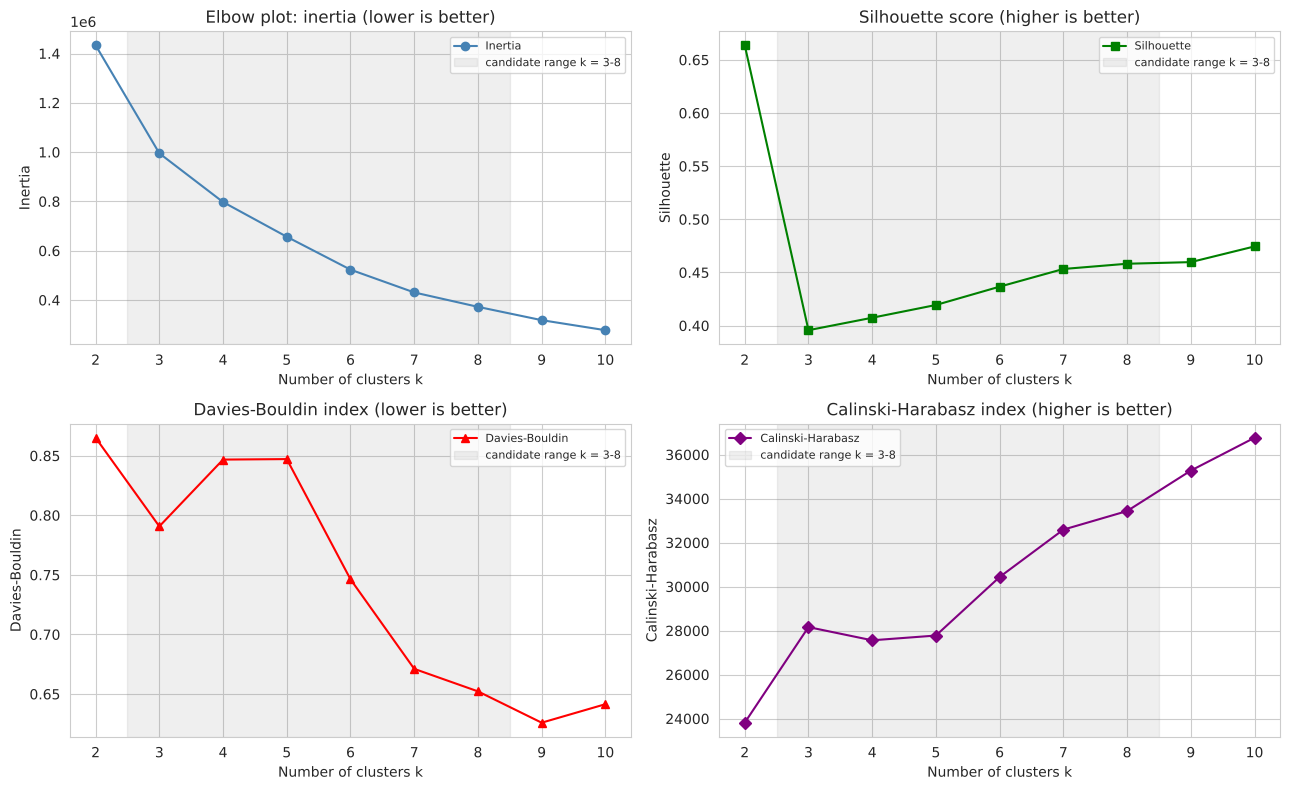

In [7]:
N_METRIC_SAMPLE = 50_000
N_SIL_SAMPLE = 10_000
rng_metric = np.random.RandomState(SEED)
metric_idx = rng_metric.choice(len(X), size=min(N_METRIC_SAMPLE, len(X)), replace=False)
X_metric = X[metric_idx]

def evaluate_k_range(Xs, ks, seed):
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(Xs)
        sizes = np.bincount(km.labels_, minlength=k)
        rows.append({
            "k": k,
            "Inertia": float(km.inertia_),
            "Silhouette": float(silhouette_score(Xs, km.labels_, sample_size=min(N_SIL_SAMPLE, len(Xs)), random_state=seed)),
            "Davies-Bouldin": float(davies_bouldin_score(Xs, km.labels_)),
            "Calinski-Harabasz": float(calinski_harabasz_score(Xs, km.labels_)),
            "Smallest cluster share": float(sizes.min() / len(Xs)),
        })
    return pd.DataFrame(rows)

def minmax(a):
    a = np.asarray(a, dtype=float)
    rng = a.max() - a.min()
    return np.zeros_like(a) if rng == 0 else (a - a.min()) / rng

def composite_score(sub):
    # equal-weight mean of normalised Silhouette (max), inverted Davies-Bouldin (min) and Calinski-Harabasz (max)
    return (minmax(sub["Silhouette"]) + (1 - minmax(sub["Davies-Bouldin"])) + minmax(sub["Calinski-Harabasz"])) / 3

K_LO, K_HI = 3, 8
def add_composites(res):
    res = res.copy()
    res["Composite (all k=2-10)"] = composite_score(res)
    res["Candidate"] = res["k"].between(K_LO, K_HI)
    res["Composite (candidates)"] = np.nan
    res.loc[res["Candidate"], "Composite (candidates)"] = composite_score(res[res["Candidate"]])
    return res

K_RANGE = list(range(2, 11))
t0 = time.time()
k_results = add_composites(evaluate_k_range(X_metric, K_RANGE, SEED))
print(f"k sweep finished in {time.time() - t0:.1f} s on {len(X_metric):,d} sampled pickups")
k_show = k_results.copy()
k_show["Composite (candidates)"] = k_show["Composite (candidates)"].map(lambda v: "-" if np.isnan(v) else f"{v:.3f}")
display(fmt_table(k_show, {"Inertia": "{:,.0f}", "Silhouette": "{:.4f}", "Davies-Bouldin": "{:.4f}", "Calinski-Harabasz": "{:,.0f}",
                           "Smallest cluster share": "{:.2%}", "Composite (all k=2-10)": "{:.3f}"}))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
panels = [("Inertia", "Elbow plot: inertia (lower is better)", "steelblue", "o"),
          ("Silhouette", "Silhouette score (higher is better)", "green", "s"),
          ("Davies-Bouldin", "Davies-Bouldin index (lower is better)", "red", "^"),
          ("Calinski-Harabasz", "Calinski-Harabasz index (higher is better)", "purple", "D")]
for ax, (col, title, colour, mk) in zip(axes.ravel(), panels):
    ax.plot(k_results["k"], k_results[col], marker=mk, color=colour, label=col)
    ax.axvspan(K_LO - 0.5, K_HI + 0.5, color="grey", alpha=0.12, label=f"candidate range k = {K_LO}-{K_HI}")
    ax.set_title(title); ax.set_xlabel("Number of clusters k"); ax.set_ylabel(col); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
# Selection of k, with sensitivity checks
cand = k_results[k_results["Candidate"]]
K_FINAL = int(cand.loc[cand["Composite (candidates)"].idxmax(), "k"])
K_UNRESTRICTED = int(k_results.loc[k_results["Composite (all k=2-10)"].idxmax(), "k"])

# Stability: repeat the sweep on 5 independent samples of 30,000 pickups
stab_rows = []
for rep in range(5):
    r_seed = SEED + 100 + rep
    idx = np.random.RandomState(r_seed).choice(len(X), size=30_000, replace=False)
    res = add_composites(evaluate_k_range(X[idx], K_RANGE, r_seed))
    c_ = res[res["Candidate"]]
    stab_rows.append({"Sample seed": r_seed,
                      f"Best k in {K_LO}-{K_HI}": int(c_.loc[c_["Composite (candidates)"].idxmax(), "k"]),
                      "Best k, unrestricted (2-10)": int(res.loc[res["Composite (all k=2-10)"].idxmax(), "k"])})
stability = pd.DataFrame(stab_rows)
display(stability)

kfin = k_results.loc[k_results["k"] == K_FINAL].iloc[0]
col_c = f"Best k in {K_LO}-{K_HI}"
n_agree = int((stability[col_c] == K_FINAL).sum())
runner_up = cand.sort_values("Composite (candidates)", ascending=False).iloc[1]
stab_vals = sorted(stability[col_c].tolist())
display(Markdown(
    f"**Result.** Among k = {K_LO}-{K_HI}, the highest composite score is at **k = {K_FINAL}** "
    f"(Silhouette {kfin['Silhouette']:.4f}, Davies-Bouldin {kfin['Davies-Bouldin']:.4f}, Calinski-Harabasz {kfin['Calinski-Harabasz']:,.0f}, composite {kfin['Composite (candidates)']:.3f}); "
    f"the runner-up is k = {int(runner_up['k'])} (composite {runner_up['Composite (candidates)']:.3f}). The smallest cluster at k = {K_FINAL} holds {kfin['Smallest cluster share']:.2%} of the sample. "
    f"Unrestricted over k = 2-10 the composite would favour k = {K_UNRESTRICTED}. "
    f"In five independent re-samples of 30,000 pickups the best k within {K_LO}-{K_HI} was {stab_vals} (equal to {K_FINAL} in {n_agree} of 5). "
    f"Calinski-Harabasz and Davies-Bouldin keep improving as k grows because the dense core is subdivided into ever smaller pieces, and the inertia curve has no sharp elbow. "
    f"The selected k is therefore a rule-based working choice, not evidence of a 'true' number of pickup zones."))

,Sample seed,Best k in 3-8,"Best k, unrestricted (2-10)"
0,142,8,8
1,143,8,10
2,144,8,10
3,145,8,10
4,146,8,8


**Result.** Among k = 3-8, the highest composite score is at **k = 8** (Silhouette 0.4582, Davies-Bouldin 0.6522, Calinski-Harabasz 33,436, composite 1.000); the runner-up is k = 7 (composite 0.893). The smallest cluster at k = 8 holds 0.34% of the sample. Unrestricted over k = 2-10 the composite would favour k = 10. In five independent re-samples of 30,000 pickups the best k within 3-8 was [8, 8, 8, 8, 8] (equal to 8 in 5 of 5). Calinski-Harabasz and Davies-Bouldin keep improving as k grows because the dense core is subdivided into ever smaller pieces, and the inertia curve has no sharp elbow. The selected k is therefore a rule-based working choice, not evidence of a 'true' number of pickup zones.

## 8. Final clustering and geographical interpretation

The selected number of clusters is fitted with `MiniBatchKMeans` on all cleaned pickups. Cluster labels are arbitrary integers; centroids are converted back to latitude/longitude with the exact inverse of the Section 5 transformation. To describe where each centroid is, distances to a few well-known reference points are computed from the coordinates (the reference coordinates are standard public landmark locations, listed in the code). A neighbourhood is only named when a centroid lies within 2 km of a reference point; otherwise only the nearest reference point and distance are given.

In [9]:
t0 = time.time()
final_model = MiniBatchKMeans(n_clusters=K_FINAL, n_init=10, batch_size=10_000, random_state=SEED).fit(X)
df["Cluster"] = final_model.labels_.astype(int)
print(f"MiniBatchKMeans (k = {K_FINAL}) fitted on {len(X):,d} pickups in {time.time() - t0:.1f} s")

cent_lat, cent_lon = to_degrees(final_model.cluster_centers_[:, 0], final_model.cluster_centers_[:, 1])
sizes = df["Cluster"].value_counts().sort_index()
centroids = pd.DataFrame({"Cluster": np.arange(K_FINAL), "Centroid lat": cent_lat, "Centroid lon": cent_lon,
                          "Pickups": sizes.values, "Share (%)": 100 * sizes.values / len(df)})

# Reference landmarks used only to describe where centroids lie (approximate public coordinates)
REFERENCE_POINTS = {
    "Times Square": (40.7580, -73.9855),
    "Wall Street / Lower Manhattan": (40.7060, -74.0088),
    "Union Square": (40.7359, -73.9911),
    "Penn Station": (40.7506, -73.9935),
    "Grand Central": (40.7527, -73.9772),
    "Central Park (south end)": (40.7679, -73.9781),
    "Columbia University": (40.8075, -73.9626),
    "LaGuardia Airport": (40.7769, -73.8740),
    "JFK Airport": (40.6413, -73.7781),
    "Newark Airport": (40.6895, -74.1745),
    "Downtown Brooklyn": (40.6928, -73.9903),
    "Williamsburg (Brooklyn)": (40.7081, -73.9571),
    "Long Island City": (40.7447, -73.9485),
}
def describe_point(lat, lon):
    d = {n: float(haversine_km(lat, lon, p[0], p[1])) for n, p in REFERENCE_POINTS.items()}
    name = min(d, key=d.get)
    return name, d[name]

near = [describe_point(la, lo) for la, lo in zip(cent_lat, cent_lon)]
centroids["Nearest reference point"] = [n for n, _ in near]
centroids["Distance (km)"] = [d for _, d in near]
centroids["Description"] = [f"within {d:.1f} km of {n}" if d <= 2.0 else f"nearest reference: {n} ({d:.1f} km away)" for n, d in near]
# within-cluster spatial spread (RMS distance to own centroid, in km)
dist_to_cent = np.linalg.norm(X - final_model.cluster_centers_[df["Cluster"].values], axis=1)
centroids["RMS radius (km)"] = [float(np.sqrt(np.mean(dist_to_cent[df["Cluster"].values == c] ** 2))) for c in range(K_FINAL)]

# Optional: relabel clusters by size so cluster 0 is always the largest (deterministic, easier to read)
order = centroids.sort_values("Pickups", ascending=False)["Cluster"].tolist()
remap = {old: new for new, old in enumerate(order)}
df["Cluster"] = df["Cluster"].map(remap).astype(int)
centroids["Cluster"] = centroids["Cluster"].map(remap)
centroids = centroids.sort_values("Cluster").reset_index(drop=True)
centers_xy = final_model.cluster_centers_[order]

display(fmt_table(centroids, {"Centroid lat": "{:.4f}", "Centroid lon": "{:.4f}", "Pickups": "{:,.0f}", "Share (%)": "{:.2f}",
                              "Distance (km)": "{:.2f}", "RMS radius (km)": "{:.2f}"}))

# Quality metrics for the final model on the fixed metric sample
lab_sample = df["Cluster"].values[metric_idx]
final_metrics = {
    "Silhouette": silhouette_score(X_metric, lab_sample, sample_size=N_SIL_SAMPLE, random_state=SEED),
    "Davies-Bouldin": davies_bouldin_score(X_metric, lab_sample),
    "Calinski-Harabasz": calinski_harabasz_score(X_metric, lab_sample),
    "Inertia (full data, km^2)": float(final_model.inertia_),
}
print("Final-model quality metrics (metrics on the fixed 50k sample):")
for k_, v_ in final_metrics.items():
    print(f"  {k_:<28s}: {v_:,.4f}")

MiniBatchKMeans (k = 8) fitted on 1,003,491 pickups in 0.9 s


,Cluster,Centroid lat,Centroid lon,Pickups,Share (%),Nearest reference point,Distance (km),Description,RMS radius (km)
0,0,40.7262,-73.9957,"351,285",35.01,Union Square,1.14,within 1.1 km of Union Square,1.80
1,1,40.7551,-73.9827,"316,439",31.53,Times Square,0.40,within 0.4 km of Times Square,1.43
2,2,40.7811,-73.9605,"133,851",13.34,Central Park (south end),2.09,nearest reference: Central Park (south end) (2...,2.13
3,3,40.6800,-73.9655,"106,303",10.59,Downtown Brooklyn,2.53,nearest reference: Downtown Brooklyn (2.5 km a...,3.67
4,4,40.7599,-73.8650,"40,129",4.00,LaGuardia Airport,2.04,nearest reference: LaGuardia Airport (2.0 km a...,3.57
5,5,40.6598,-73.7662,"29,595",2.95,JFK Airport,2.29,nearest reference: JFK Airport (2.3 km away),6.74
6,6,40.8765,-73.9008,"16,064",1.60,Columbia University,9.27,nearest reference: Columbia University (9.3 km...,9.40
7,7,40.6996,-74.1984,"9,825",0.98,Newark Airport,2.31,nearest reference: Newark Airport (2.3 km away),7.96


Final-model quality metrics (metrics on the fixed 50k sample):
  Silhouette                  : 0.4057
  Davies-Bouldin              : 0.7005
  Calinski-Harabasz           : 32,410.8824
  Inertia (full data, km^2)   : 7,721,745.8992


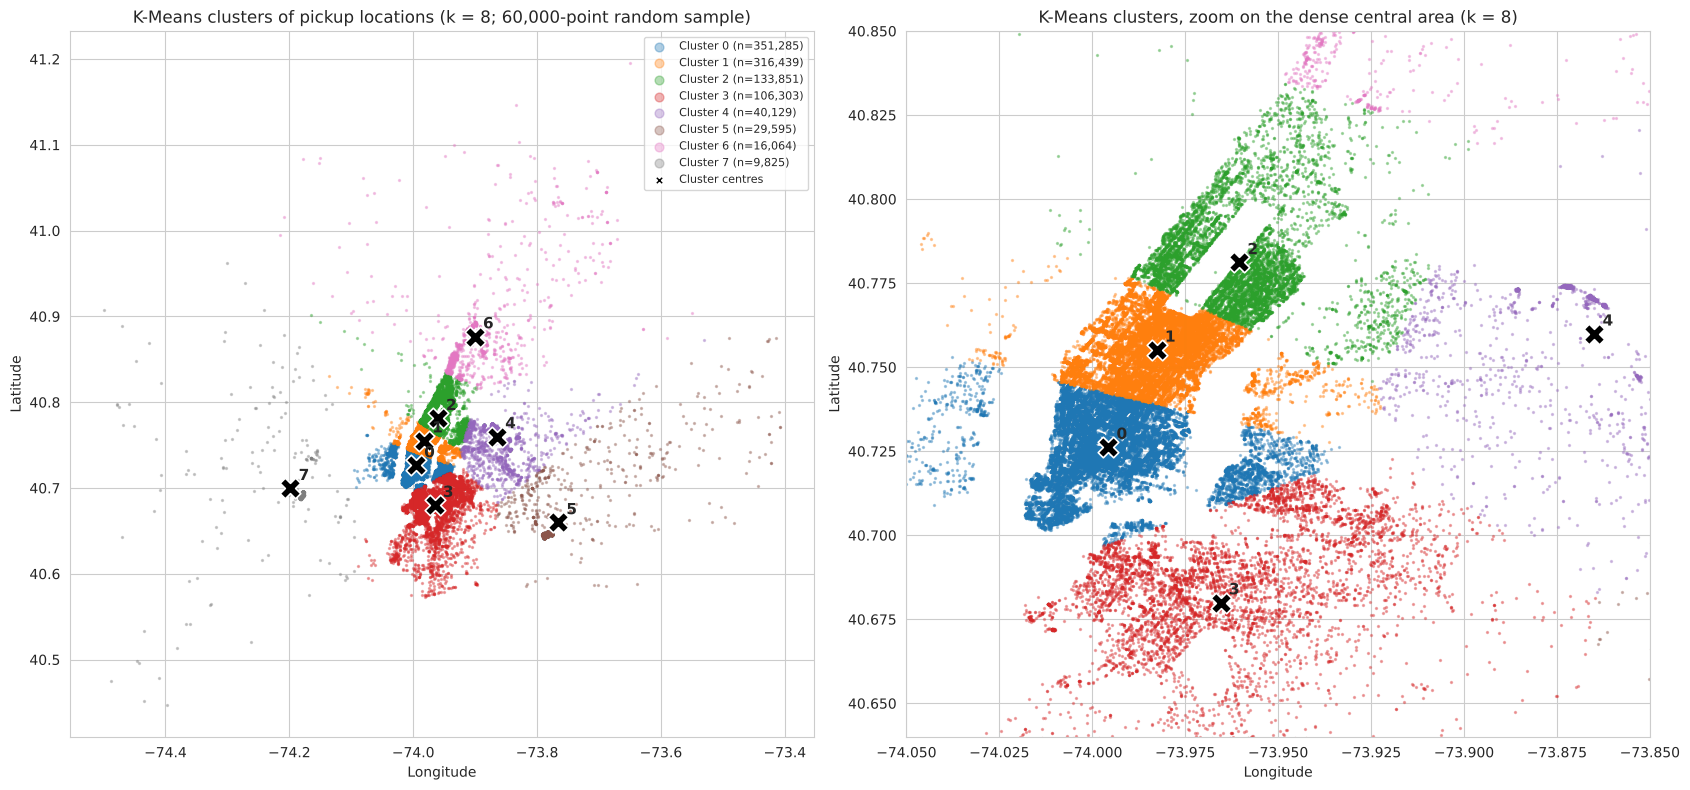

**Interpretation.** The k = 8 clusters have between 9,825 and 351,285 pickups (1.0% to 35.0% of the data). The largest cluster (cluster 0) has its centre at (40.7262, -73.9957), within 1.1 km of Union Square. The smallest cluster (cluster 7) is centred at (40.6996, -74.1984), nearest reference: Newark Airport (2.3 km away), with an RMS radius of 8.0 km, versus 1.4-9.4 km across all clusters. Descriptions rely only on distances from centroids to the listed reference points; a centroid is a mean position, so it need not coincide with any named place.

In [10]:
# Geographic scatter plot (random subsample per cluster for readability; centroids use all data)
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
palette = plt.cm.tab10(np.linspace(0, 1, 10))[:K_FINAL] if K_FINAL <= 10 else plt.cm.tab20(np.linspace(0, 1, K_FINAL))
plot_sample = df.sample(60_000, random_state=SEED)

for ax_i, (ax, zoom) in enumerate(zip(axes, [False, True])):
    for c in range(K_FINAL):
        sub = plot_sample[plot_sample["Cluster"] == c]
        ax.scatter(sub["Lon"], sub["Lat"], s=2, alpha=0.35, color=palette[c],
                   label=f"Cluster {c} (n={int(centroids.loc[c,'Pickups']):,d})")
    ax.scatter(centroids["Centroid lon"], centroids["Centroid lat"], marker="X", s=220, c="black", edgecolors="white", linewidths=1.2, label="Cluster centres", zorder=5)
    for c in range(K_FINAL):
        ax.annotate(str(c), (centroids.loc[c, "Centroid lon"], centroids.loc[c, "Centroid lat"]), xytext=(6, 6), textcoords="offset points",
                    fontsize=11, fontweight="bold", zorder=6)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    if zoom:
        ax.set_xlim(-74.05, -73.85); ax.set_ylim(40.64, 40.85)
        ax.set_title(f"K-Means clusters, zoom on the dense central area (k = {K_FINAL})")
    else:
        ax.set_title(f"K-Means clusters of pickup locations (k = {K_FINAL}; 60,000-point random sample)")
        leg = ax.legend(fontsize=8, loc="upper right")
        for handle in leg.legend_handles:          # fixed legend marker size (markerscale would inflate the centroid marker)
            handle.set_sizes([40])
plt.tight_layout(); plt.show()

big = centroids.iloc[0]; small = centroids.sort_values("Pickups").iloc[0]
display(Markdown(
    f"**Interpretation.** The k = {K_FINAL} clusters have between {centroids['Pickups'].min():,.0f} and {centroids['Pickups'].max():,.0f} pickups "
    f"({centroids['Share (%)'].min():.1f}% to {centroids['Share (%)'].max():.1f}% of the data). "
    f"The largest cluster (cluster {int(big['Cluster'])}) has its centre at ({big['Centroid lat']:.4f}, {big['Centroid lon']:.4f}), {big['Description']}. "
    f"The smallest cluster (cluster {int(small['Cluster'])}) is centred at ({small['Centroid lat']:.4f}, {small['Centroid lon']:.4f}), {small['Description']}, "
    f"with an RMS radius of {small['RMS radius (km)']:.1f} km, versus {centroids['RMS radius (km)'].min():.1f}-{centroids['RMS radius (km)'].max():.1f} km across all clusters. "
    f"Descriptions rely only on distances from centroids to the listed reference points; a centroid is a mean position, so it need not coincide with any named place."))

## 9. Alternative clustering comparison: DBSCAN (haversine)

**DBSCAN** groups points that are *density-reachable*: a point with at least `min_samples` neighbours within distance `eps` is a core point, clusters are chains of core points plus their border points, and everything else is labelled **noise** (−1). It needs no preset number of clusters and can find irregular shapes, but a single `eps` cannot suit both very dense and sparse areas.

* **Distance metric.** The `haversine` metric on coordinates in radians measures great-circle distance, so `eps` (in km) is converted to radians by dividing by the Earth radius.
* **min_samples = 20.** A core point needs at least 20 sample points within `eps`.
* **eps.** Because the result depends strongly on `eps`, a small grid is reported together with a k-distance plot (distance to the 20th nearest neighbour). The primary value, **0.3 km** (about the length of a Manhattan block), is a judgement, not an optimum.
* **Sample.** DBSCAN is run on a fixed random sample of 30,000 pickups (3% of the data), so the sample is *sparser* than the full data and cluster counts are not comparable with a full-data run.
* **How it differs from K-Means.** K-Means assigns *every* point to one of *k* compact groups and partitions even the dense core. DBSCAN can leave sparse points as noise and merges dense areas that are connected. Producing clusters in both methods is therefore **not** evidence that either validates the other.

,eps (km),Clusters,Noise points,Noise (%),Largest cluster share of clustered pts (%)
0,0.1000,70,8488,28.29,77.53
1,0.2000,42,4218,14.06,83.79
2,0.3000,27,2703,9.01,80.22
3,0.5000,15,1521,5.07,78.29
4,1.0000,8,760,2.53,95.53


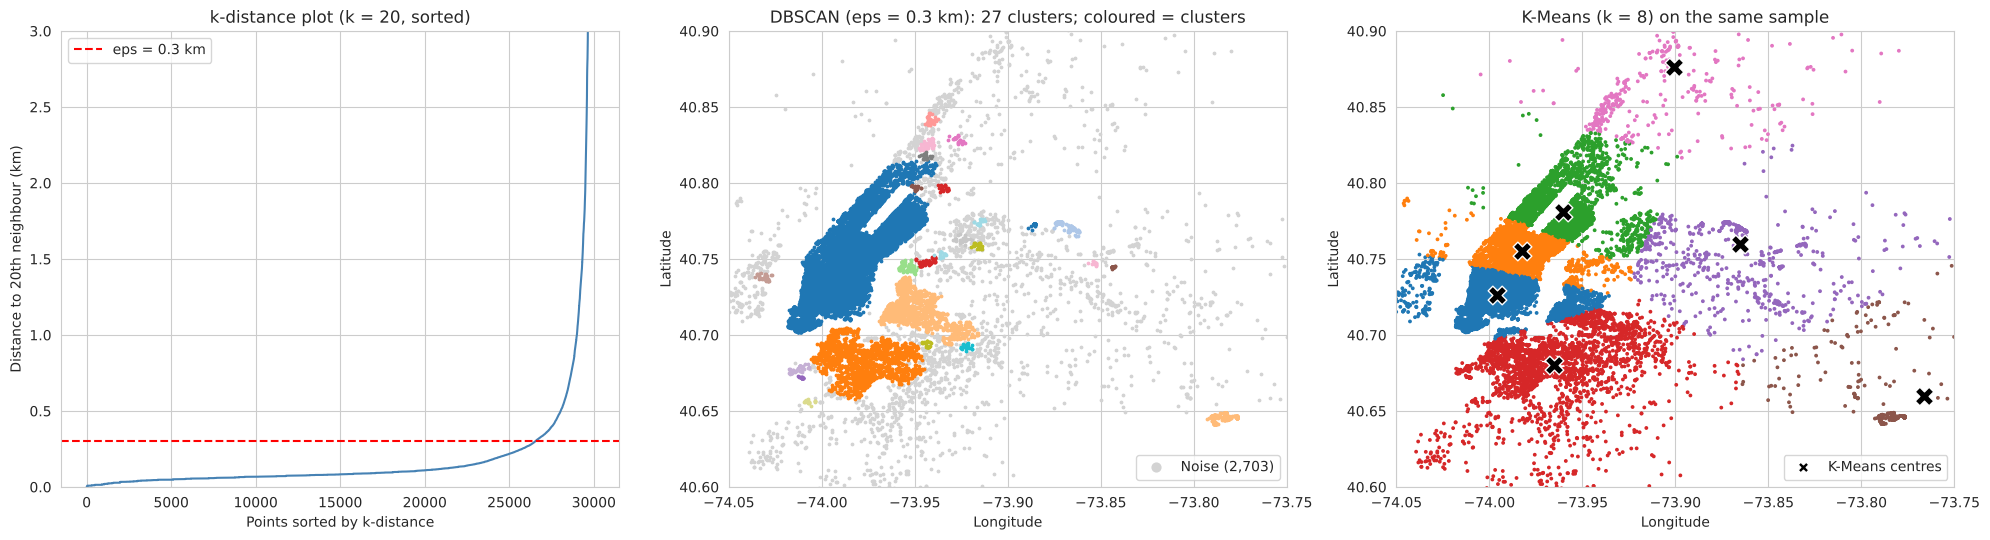

DBSCAN label (-1 = noise),-1,0,3,4,5,2,6
K-Means cluster,,,,,,,
0,169,9172,144,839,0,0,0
1,115,9158,0,63,0,0,0
2,368,3569,0,0,0,0,0
3,901,0,1642,497,0,0,0
4,480,0,0,0,0,553,0
5,215,0,0,0,724,0,0
6,381,0,0,0,0,0,0
7,74,0,0,0,0,0,212


**Interpretation.** With eps = 0.3 km and min_samples = 20, DBSCAN finds **27 clusters** and labels **2,703 of 30,000 sampled points (9.0%) as noise**. The largest DBSCAN cluster contains 80.2% of all clustered points, i.e. the dense central area is connected into one very large density region, which K-Means splits into several compact zones. The eps grid shows the result is sensitive to eps (from 8 to 70 clusters and 2.5% to 28.3% noise). The two methods answer different questions (compact partition versus connected dense regions), so agreement or disagreement between them is not a validation of K-Means.

In [11]:
from sklearn.neighbors import NearestNeighbors

DB_SAMPLE_N, DB_MIN_SAMPLES = 30_000, 20
db_idx = np.random.RandomState(SEED).choice(len(df), size=DB_SAMPLE_N, replace=False)
db_sample = df.iloc[db_idx]
db_coords_rad = np.radians(db_sample[["Lat", "Lon"]].to_numpy())

# k-distance plot (distance to the min_samples-th nearest neighbour, including the point itself)
nn = NearestNeighbors(n_neighbors=DB_MIN_SAMPLES, metric="haversine", algorithm="ball_tree").fit(db_coords_rad)
kdist_km = np.sort(nn.kneighbors(db_coords_rad)[0][:, -1] * EARTH_RADIUS_KM)

# sensitivity grid over eps
grid_rows, db_models = [], {}
for eps_km in [0.1, 0.2, 0.3, 0.5, 1.0]:
    m = DBSCAN(eps=eps_km / EARTH_RADIUS_KM, min_samples=DB_MIN_SAMPLES, metric="haversine", algorithm="ball_tree").fit(db_coords_rad)
    lab = m.labels_
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    cl_sizes = np.bincount(lab[lab >= 0]) if n_cl else np.array([0])
    grid_rows.append({"eps (km)": eps_km, "Clusters": n_cl, "Noise points": int((lab == -1).sum()),
                      "Noise (%)": 100 * (lab == -1).mean(),
                      "Largest cluster share of clustered pts (%)": 100 * cl_sizes.max() / max(cl_sizes.sum(), 1)})
    db_models[eps_km] = lab
db_grid = pd.DataFrame(grid_rows)
display(fmt_table(db_grid, {"Noise (%)": "{:.2f}", "Largest cluster share of clustered pts (%)": "{:.2f}"}))

EPS_PRIMARY_KM = 0.3
db_labels = db_models[EPS_PRIMARY_KM]
n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_db_noise = int((db_labels == -1).sum())

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].plot(kdist_km, color="steelblue")
axes[0].axhline(EPS_PRIMARY_KM, color="red", ls="--", label=f"eps = {EPS_PRIMARY_KM} km")
axes[0].set_title(f"k-distance plot (k = {DB_MIN_SAMPLES}, sorted)"); axes[0].set_xlabel("Points sorted by k-distance"); axes[0].set_ylabel("Distance to 20th neighbour (km)")
axes[0].set_ylim(0, min(3, kdist_km.max())); axes[0].legend()

noise = db_labels == -1
axes[1].scatter(db_sample["Lon"][noise], db_sample["Lat"][noise], s=3, color="lightgrey", label=f"Noise ({n_db_noise:,d})")
clustered_ids = np.unique(db_labels[~noise])
cmap = plt.cm.tab20(np.linspace(0, 1, max(len(clustered_ids), 1)))
for i, cid in enumerate(clustered_ids):
    msk = db_labels == cid
    axes[1].scatter(db_sample["Lon"][msk], db_sample["Lat"][msk], s=3, color=cmap[i % len(cmap)])
axes[1].set_title(f"DBSCAN (eps = {EPS_PRIMARY_KM} km): {n_db_clusters} clusters; coloured = clusters")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude"); axes[1].set_xlim(-74.05, -73.75); axes[1].set_ylim(40.6, 40.9); leg1 = axes[1].legend()
for handle in leg1.legend_handles:
    handle.set_sizes([40])

axes[2].scatter(db_sample["Lon"], db_sample["Lat"], s=3, c=[palette[c] for c in db_sample["Cluster"]])
axes[2].scatter(centroids["Centroid lon"], centroids["Centroid lat"], marker="X", s=180, c="black", edgecolors="white", zorder=5, label="K-Means centres")
axes[2].set_title(f"K-Means (k = {K_FINAL}) on the same sample"); axes[2].set_xlabel("Longitude"); axes[2].set_ylabel("Latitude")
axes[2].set_xlim(-74.05, -73.75); axes[2].set_ylim(40.6, 40.9); leg2 = axes[2].legend()
for handle in leg2.legend_handles:
    handle.set_sizes([60])
plt.tight_layout(); plt.show()

# cross-tabulation K-Means vs DBSCAN (largest DBSCAN clusters only, to keep the table readable)
ct = pd.crosstab(pd.Series(db_sample["Cluster"].values, name="K-Means cluster"), pd.Series(db_labels, name="DBSCAN label (-1 = noise)"))
top_cols = [-1] + [c for c in ct.sum().sort_values(ascending=False).index if c != -1][:6]
display(ct[[c for c in top_cols if c in ct.columns]])

sizes_db = np.bincount(db_labels[db_labels >= 0]) if n_db_clusters else np.array([0])
largest_share = 100 * sizes_db.max() / max(sizes_db.sum(), 1)
display(Markdown(
    f"**Interpretation.** With eps = {EPS_PRIMARY_KM} km and min_samples = {DB_MIN_SAMPLES}, DBSCAN finds **{n_db_clusters} clusters** and labels **{n_db_noise:,d} of {DB_SAMPLE_N:,d} sampled points "
    f"({100*n_db_noise/DB_SAMPLE_N:.1f}%) as noise**. The largest DBSCAN cluster contains {largest_share:.1f}% of all clustered points, i.e. the dense central area is connected into one very large density region, "
    f"which K-Means splits into several compact zones. The eps grid shows the result is sensitive to eps (from {db_grid['Clusters'].min()} to {db_grid['Clusters'].max()} clusters and "
    f"{db_grid['Noise (%)'].min():.1f}% to {db_grid['Noise (%)'].max():.1f}% noise). The two methods answer different questions "
    f"(compact partition versus connected dense regions), so agreement or disagreement between them is not a validation of K-Means."))

## 10. Cluster activity by hour

* **Raw counts** show how many pickups each cluster receives at each hour; large clusters dominate such a plot.
* **Normalised proportions** divide each cluster's hourly counts by that cluster's total, so each row of the heatmap sums to 100%. This shows the *shape* of each cluster's daily profile independently of its size, which is what is needed to compare timing across clusters.

Cluster x hour pickup counts:


Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Cluster,,,,,,,,,,,,,,,,,,,,,
0,12006,8484,5389,4300,4127,6267,9850,13372,14326,11971,...,16611,19067,20786,23250,24597,23931,22486,22297,20758,16627
1,5358,3333,2315,2451,2667,3985,6580,10789,11918,10791,...,16737,21884,25684,28031,27748,24266,20746,18411,14483,8879
2,1583,970,743,1318,1892,3559,8226,10043,9058,6798,...,7344,8048,8571,8562,8347,7046,6025,5587,4246,2597
3,3206,2158,1457,1657,2081,3320,4403,4890,4783,4620,...,4626,4736,5285,5930,6371,6451,6399,6503,5679,4339
4,481,300,237,346,416,708,1196,1452,1829,1916,...,1994,2356,2545,2714,2874,2754,2995,2629,2147,1077
5,425,181,98,153,748,1235,1308,722,589,627,...,2476,1941,2058,1569,1818,2124,2295,1995,1940,1380
6,354,199,170,250,315,479,647,698,664,697,...,942,877,916,885,823,757,995,1115,757,503
7,176,97,35,69,180,238,266,292,270,254,...,592,825,717,629,630,663,597,631,606,366


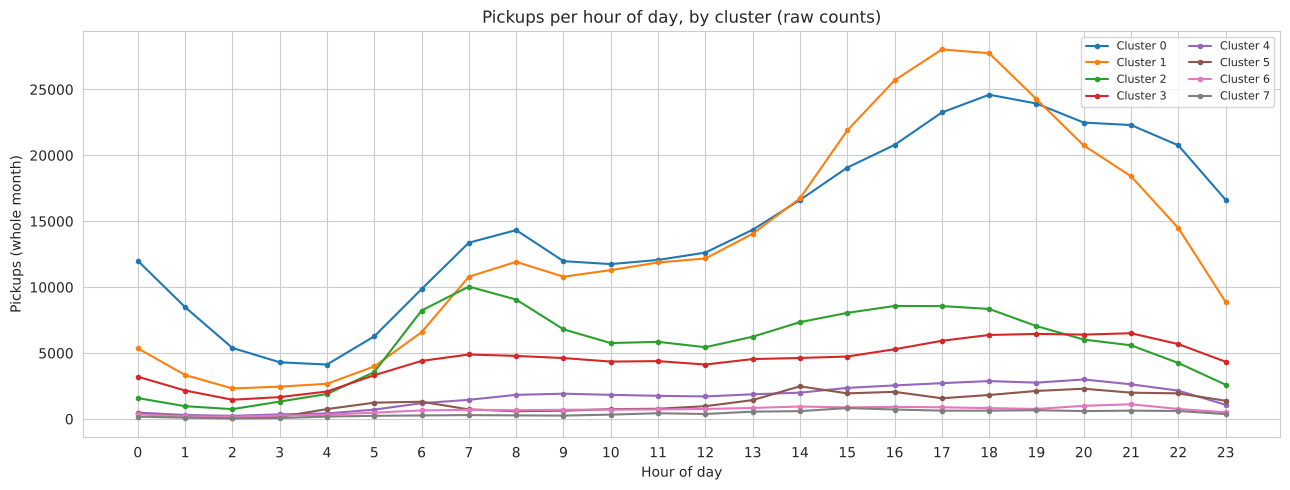

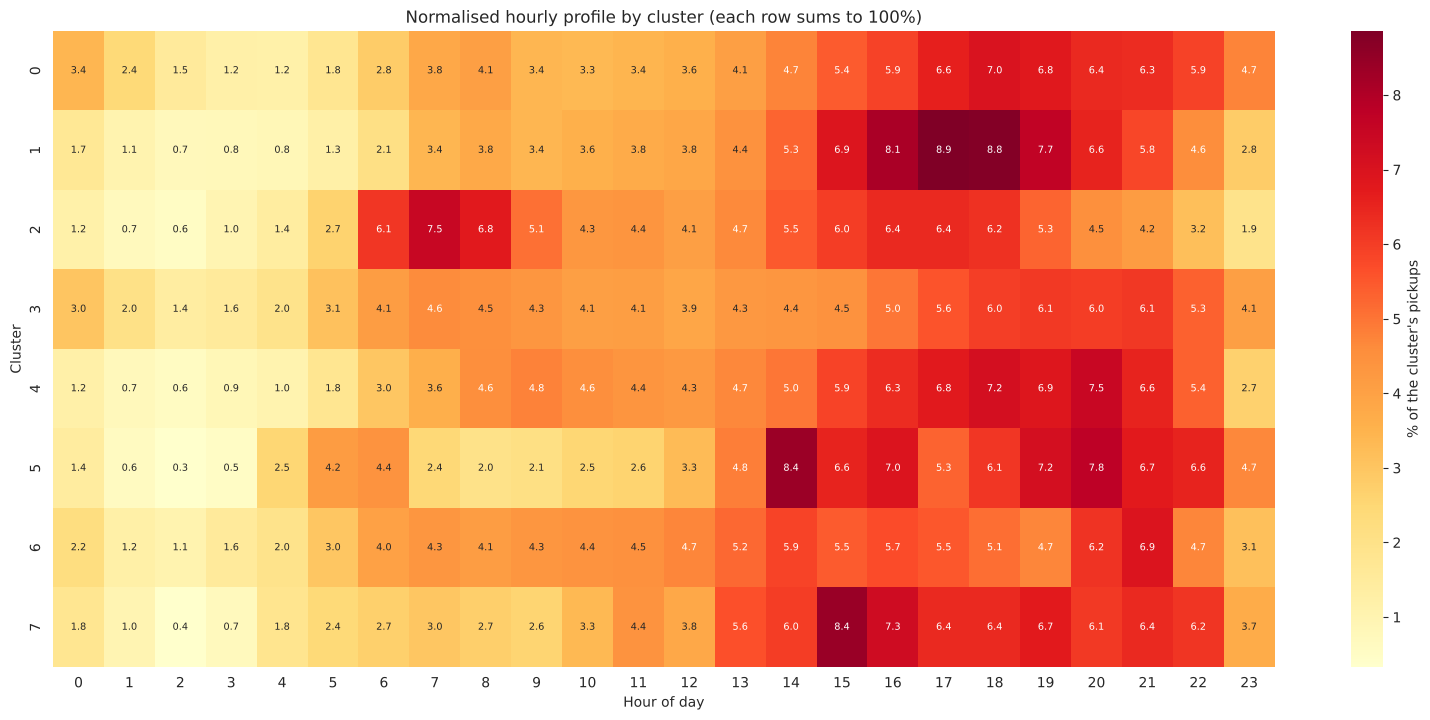

,Cluster,Peak hour,Pickups at peak hour,Share of cluster's pickups at peak (%),Quietest hour,Share 06-10h (%),Share 17-21h (%),Share 00-04h (%)
0,0,18:00,24597,7.00,04:00,17.4,33.2,9.8
1,1,17:00,28031,8.86,02:00,16.2,37.7,5.1
2,2,07:00,10043,7.50,02:00,29.8,26.6,4.9
3,3,21:00,6503,6.12,02:00,21.7,29.8,9.9
4,4,20:00,2995,7.46,02:00,20.5,34.8,4.4
5,5,14:00,2476,8.37,02:00,13.5,33.1,5.4
6,6,21:00,1115,6.94,02:00,21.3,28.5,8.0
7,7,15:00,825,8.40,02:00,14.4,32.1,5.7


**Interpretation.** City-wide, 19.2% of pickups occur between 06:00 and 10:59, 33.3% between 17:00 and 21:59 and 7.2% between 00:00 and 04:59. Peak hours across clusters range from 07:00 to 21:00. Cluster 1 has the largest evening share (17-21h: 37.7%), while cluster 3 has the largest share in the 00-04h window (9.9%). Cluster 3 has the flattest daily profile and cluster 1 the most peaked one (measured by the standard deviation of its hourly shares). These differences describe *when* each zone is active; they do not by themselves identify land use (residential, commercial, nightlife) because no such information is in the data.

In [12]:
pivot_hour = df.groupby(["Cluster", "Hour"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
pivot_hour_share = pivot_hour.div(pivot_hour.sum(axis=1), axis=0) * 100

print("Cluster x hour pickup counts:")
display(pivot_hour)

fig, ax = plt.subplots(figsize=(13, 5))
for c in pivot_hour.index:
    ax.plot(pivot_hour.columns, pivot_hour.loc[c], marker="o", ms=3, color=palette[c], label=f"Cluster {c}")
ax.set_title("Pickups per hour of day, by cluster (raw counts)"); ax.set_xlabel("Hour of day"); ax.set_ylabel("Pickups (whole month)")
ax.set_xticks(range(24)); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

plt.figure(figsize=(16, 0.6 * K_FINAL + 2.5))
sns.heatmap(pivot_hour_share, annot=True, fmt=".1f", cmap="YlOrRd", annot_kws={"size": 7}, cbar_kws={"label": "% of the cluster's pickups"})
plt.title("Normalised hourly profile by cluster (each row sums to 100%)"); plt.xlabel("Hour of day"); plt.ylabel("Cluster")
plt.tight_layout(); plt.show()

city_share = pivot_hour.sum(axis=0) / pivot_hour.values.sum() * 100
peak_rows = []
for c in pivot_hour.index:
    ph = int(pivot_hour.loc[c].idxmax()); th = int(pivot_hour.loc[c].idxmin())
    peak_rows.append({"Cluster": c, "Peak hour": f"{ph:02d}:00", "Pickups at peak hour": int(pivot_hour.loc[c, ph]),
                      "Share of cluster's pickups at peak (%)": pivot_hour_share.loc[c, ph],
                      "Quietest hour": f"{th:02d}:00",
                      "Share 06-10h (%)": pivot_hour_share.loc[c, 6:10].sum(), "Share 17-21h (%)": pivot_hour_share.loc[c, 17:21].sum(),
                      "Share 00-04h (%)": pivot_hour_share.loc[c, 0:4].sum()})
peak_table = pd.DataFrame(peak_rows)
city_row = {"06-10h": city_share.loc[6:10].sum(), "17-21h": city_share.loc[17:21].sum(), "00-04h": city_share.loc[0:4].sum()}
display(fmt_table(peak_table, {"Share of cluster's pickups at peak (%)": "{:.2f}", "Share 06-10h (%)": "{:.1f}", "Share 17-21h (%)": "{:.1f}", "Share 00-04h (%)": "{:.1f}"}))

late = peak_table.sort_values("Share 00-04h (%)", ascending=False).iloc[0]
eve = peak_table.sort_values("Share 17-21h (%)", ascending=False).iloc[0]
flat = pivot_hour_share.std(axis=1).idxmin(); peaky = pivot_hour_share.std(axis=1).idxmax()
display(Markdown(
    f"**Interpretation.** City-wide, {city_row['06-10h']:.1f}% of pickups occur between 06:00 and 10:59, {city_row['17-21h']:.1f}% between 17:00 and 21:59 and {city_row['00-04h']:.1f}% between 00:00 and 04:59. "
    f"Peak hours across clusters range from {peak_table['Peak hour'].min()} to {peak_table['Peak hour'].max()}. "
    f"Cluster {int(eve['Cluster'])} has the largest evening share (17-21h: {eve['Share 17-21h (%)']:.1f}%), while cluster {int(late['Cluster'])} has the largest share in the 00-04h window ({late['Share 00-04h (%)']:.1f}%). "
    f"Cluster {flat} has the flattest daily profile and cluster {peaky} the most peaked one (measured by the standard deviation of its hourly shares). "
    f"These differences describe *when* each zone is active; they do not by themselves identify land use (residential, commercial, nightlife) because no such information is in the data."))

## 11. Cluster activity by date

Daily counts per cluster across September 2014. For the weekday/weekend comparison, the average number of pickups **per day** is used (September 2014 contains 22 weekdays and 8 weekend days, so raw totals would be misleading). Monday 1 September 2014 was the US Labor Day public holiday; it is classified as a weekday here because the dataset has no holiday indicator.

Cluster x date pickup counts (rows = clusters):


Date,2014-09-01,2014-09-02,2014-09-03,2014-09-04,2014-09-05,2014-09-06,2014-09-07,2014-09-08,2014-09-09,2014-09-10,...,2014-09-21,2014-09-22,2014-09-23,2014-09-24,2014-09-25,2014-09-26,2014-09-27,2014-09-28,2014-09-29,2014-09-30
Cluster,,,,,,,,,,,,,,,,,,,,,
0,5661,8808,10919,13045,15334,15888,10637,9759,11554,12193,...,10654,8737,9915,10098,12827,13498,14481,9745,8755,10748
1,4653,9023,11031,13355,13824,10660,7402,10147,12400,12948,...,6527,9091,9852,9795,11853,10828,10033,6986,9435,11634
2,2381,3861,4041,4544,5222,5030,3518,4133,4320,4371,...,3278,4073,4260,4585,5839,4993,5557,3630,4047,4636
3,2793,2589,2878,3070,3895,5183,4063,2637,3060,2986,...,3500,2554,2885,3233,3580,4158,5410,4570,2911,2979
4,1723,1731,1384,1656,1287,1238,1618,1290,976,1004,...,1803,1231,1027,1136,1342,1336,1156,1571,1387,1012
5,1547,1306,931,984,1003,771,1297,1043,691,798,...,1355,1050,769,840,865,859,800,1364,1124,803
6,365,474,492,520,592,666,578,404,491,468,...,497,509,552,559,546,518,701,614,444,490
7,429,412,315,304,281,230,360,324,315,312,...,384,361,282,254,358,333,252,422,372,271


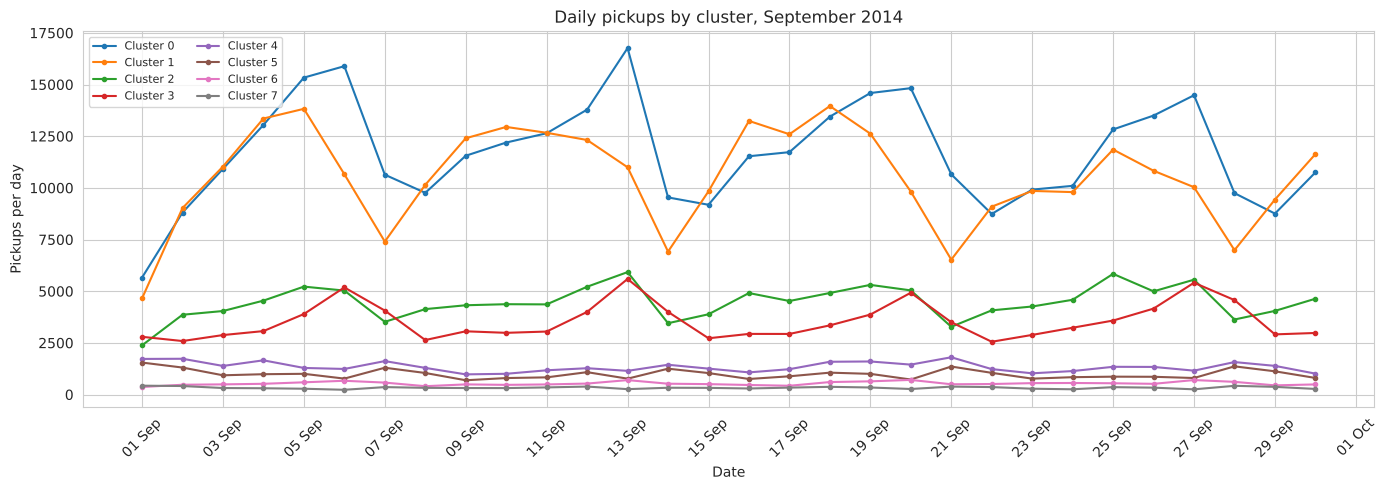

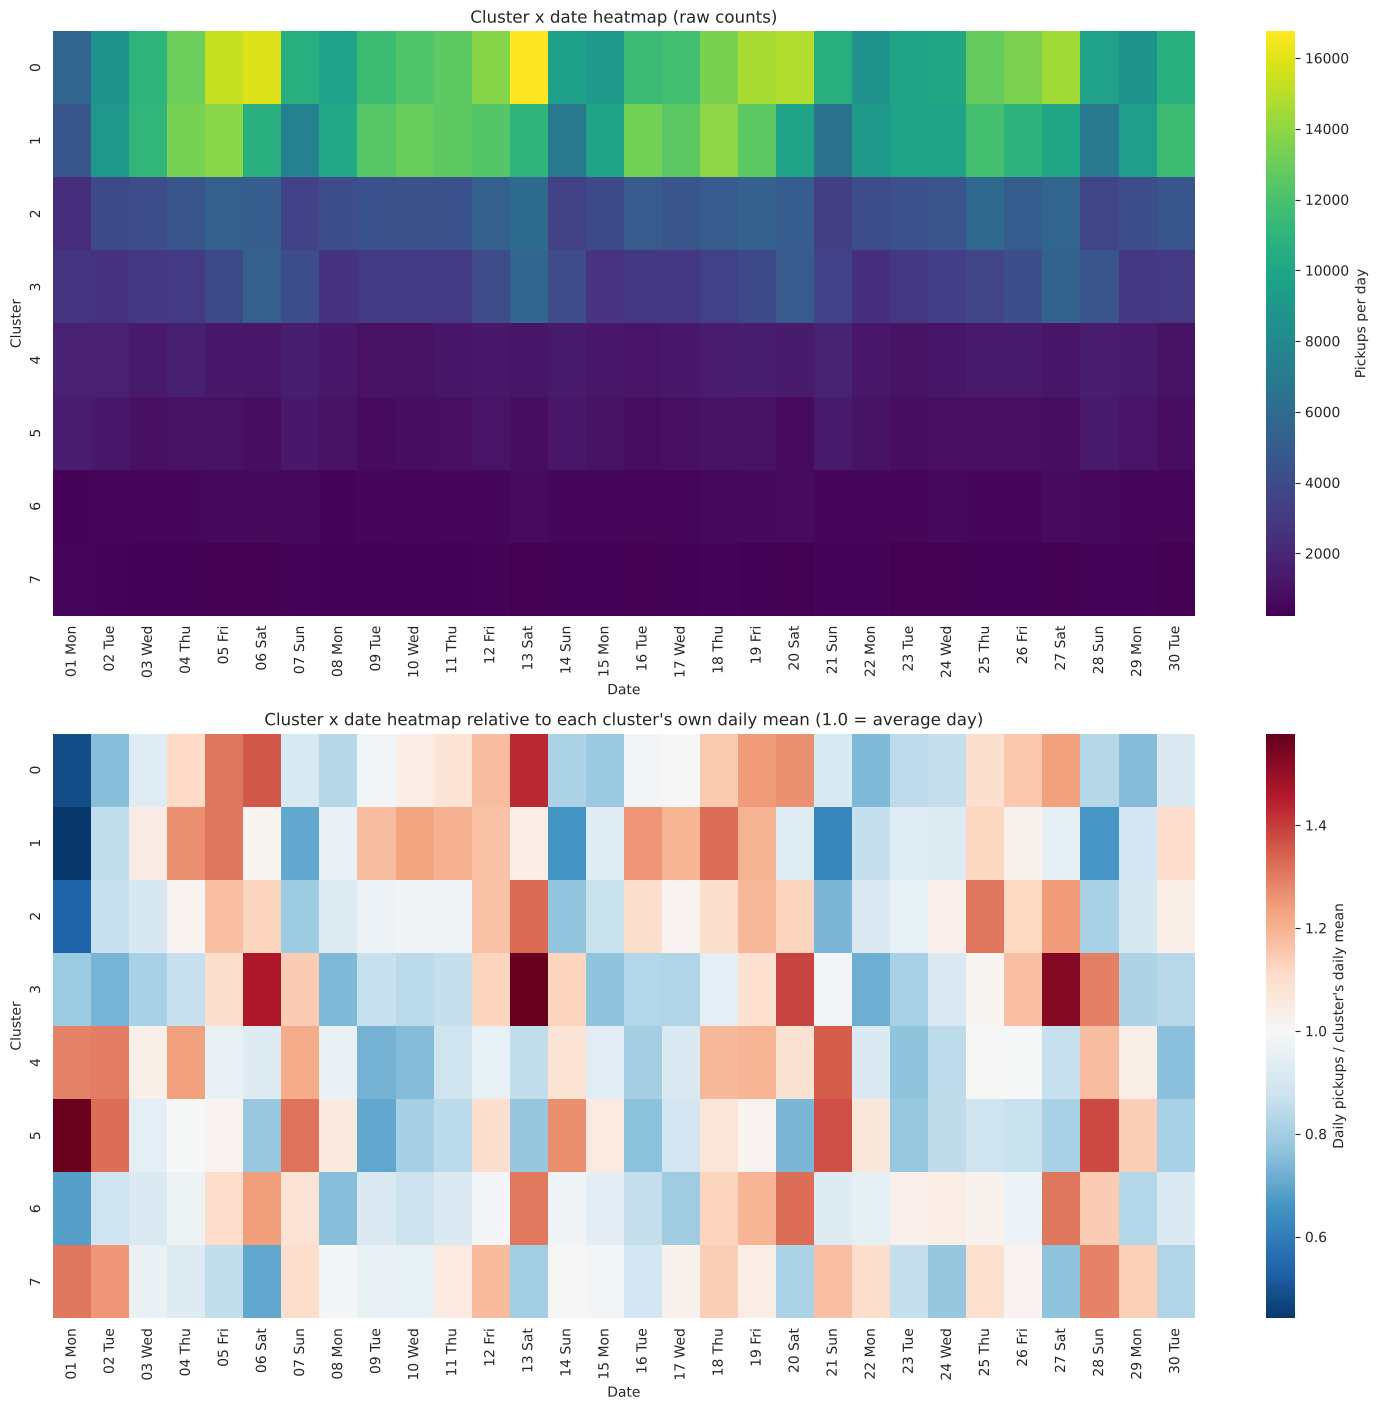

,Avg per weekday,Avg per weekend day,Weekend / weekday ratio
Cluster,,,
0,"11,307","12,816",1.133
1,"11,232","8,668",0.772
2,"4,474","4,428",0.990
3,"3,139","4,656",1.483
4,"1,305","1,428",1.094
5,966,"1,042",1.078
6,504,623,1.238
7,333,313,0.942


Days in data: 22 weekdays, 8 weekend days. City-wide weekend/weekday ratio: 1.021


**Interpretation.** City-wide, an average weekend day has 1.02 times the pickups of an average weekday. Cluster 3 is the most weekend-weighted (ratio 1.48) and cluster 1 the most weekday-weighted (ratio 0.77). The busiest day overall is Sat 13 Sep and the quietest is Mon 01 Sep. Clusters whose ratio is above the city-wide value are relatively more active at weekends than the city as a whole. With a single month of data, each weekday occurs only four or five times, so these ratios are descriptive and could shift with other months, weather or events.

In [13]:
pivot_date = df.groupby(["Cluster", "Date"]).size().unstack(fill_value=0)
pivot_date.columns = pd.to_datetime(pivot_date.columns)
print("Cluster x date pickup counts (rows = clusters):")
display(pivot_date)

fig, ax = plt.subplots(figsize=(14, 5))
for c in pivot_date.index:
    ax.plot(pivot_date.columns, pivot_date.loc[c], marker="o", ms=3, color=palette[c], label=f"Cluster {c}")
ax.set_title("Daily pickups by cluster, September 2014"); ax.set_xlabel("Date"); ax.set_ylabel("Pickups per day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.xaxis.set_major_locator(mdates.DayLocator(interval=2)); ax.tick_params(axis="x", rotation=45)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 1, figsize=(15, 0.9 * K_FINAL + 7))
day_labels = [d.strftime("%d %a") for d in pivot_date.columns]
sns.heatmap(pivot_date.set_axis(day_labels, axis=1), cmap="viridis", ax=axes[0], cbar_kws={"label": "Pickups per day"})
axes[0].set_title("Cluster x date heatmap (raw counts)"); axes[0].set_xlabel("Date"); axes[0].set_ylabel("Cluster")
rel = pivot_date.div(pivot_date.mean(axis=1), axis=0)
sns.heatmap(rel.set_axis(day_labels, axis=1), cmap="RdBu_r", center=1.0, ax=axes[1], cbar_kws={"label": "Daily pickups / cluster's daily mean"})
axes[1].set_title("Cluster x date heatmap relative to each cluster's own daily mean (1.0 = average day)"); axes[1].set_xlabel("Date"); axes[1].set_ylabel("Cluster")
plt.tight_layout(); plt.show()

# weekday vs weekend, per-day averages
day_type = df.drop_duplicates("Date").set_index("Date")["IsWeekend"]
n_weekend_days, n_weekday_days = int(day_type.sum()), int((1 - day_type).sum())
cnt = df.groupby(["Cluster", "IsWeekend"]).size().unstack(fill_value=0)
wk = pd.DataFrame({"Avg per weekday": cnt[0] / n_weekday_days, "Avg per weekend day": cnt[1] / n_weekend_days})
wk["Weekend / weekday ratio"] = wk["Avg per weekend day"] / wk["Avg per weekday"]
city_ratio = (cnt[1].sum() / n_weekend_days) / (cnt[0].sum() / n_weekday_days)
display(fmt_table(wk, {"Avg per weekday": "{:,.0f}", "Avg per weekend day": "{:,.0f}", "Weekend / weekday ratio": "{:.3f}"}))
print(f"Days in data: {n_weekday_days} weekdays, {n_weekend_days} weekend days. City-wide weekend/weekday ratio: {city_ratio:.3f}")

hi, lo = wk["Weekend / weekday ratio"].idxmax(), wk["Weekend / weekday ratio"].idxmin()
busiest_day = pivot_date.sum().idxmax(); quietest_day = pivot_date.sum().idxmin()
display(Markdown(
    f"**Interpretation.** City-wide, an average weekend day has {city_ratio:.2f} times the pickups of an average weekday. "
    f"Cluster {hi} is the most weekend-weighted (ratio {wk.loc[hi, 'Weekend / weekday ratio']:.2f}) and cluster {lo} the most weekday-weighted (ratio {wk.loc[lo, 'Weekend / weekday ratio']:.2f}). "
    f"The busiest day overall is {busiest_day:%a %d %b} and the quietest is {quietest_day:%a %d %b}. "
    f"Clusters whose ratio is above the city-wide value are relatively more active at weekends than the city as a whole. "
    f"With a single month of data, each weekday occurs only four or five times, so these ratios are descriptive and could shift with other months, weather or events."))

## 12. Time-series forecasting

**Data preparation.** Pickups are aggregated to hourly counts for the whole city. The hourly index is rebuilt as a complete regular grid from the first to the last hour; any hour without pickups is kept as **0** rather than dropped, so that the seasonal structure is preserved.

**Chronological split (no shuffling, no leakage).** The **last 168 hours (7 days)** form the test set; all earlier hours form the training set. Every model is fitted using the training data only and produces a multi-step forecast for the whole test window from a single forecast origin. Test observations are never used for fitting, parameter estimation or seasonal initialisation.

**Models.**
1. *Seasonal naive, 24 h:* repeat the last training day.
2. *Seasonal naive, 168 h:* repeat the last training week (captures the weekday/weekend pattern).
3. *Holt-Winters, additive trend, 24 h seasonality.*
4. *Holt-Winters, no trend, 24 h seasonality* (a trend extrapolated for a whole week can drift badly).
5. *Holt-Winters, no trend, 168 h seasonality* (needs at least two full weekly cycles, available in the training data).
6. *SARIMA(1,1,1)(1,1,1)₂₄* and 7. *SARIMA(1,0,1)(1,1,1)₂₄* (seasonal differencing of order 24; a weekly SARIMA with period 168 is too memory-intensive to fit reliably).

**Metrics (test set only).** MAE and RMSE are in trips per hour. **MAPE** is computed only over hours with a non-zero actual value (a percentage error is undefined when the actual is 0); the number of excluded hours is reported.

**Model selection caveat.** Several candidate models are compared on the same test window and the best is chosen from them. This is what the assignment requires, but it makes the winner's score slightly optimistic, and models with very similar errors should not be regarded as truly different.

In [14]:
# --- hourly series on a complete regular grid; zero-trip hours preserved ---
hourly_counts = df.set_index("Date/Time").resample("h").size()
full_index = pd.date_range(hourly_counts.index.min(), hourly_counts.index.max(), freq="h")
hourly = hourly_counts.reindex(full_index, fill_value=0).astype(float)
hourly.index.freq = "h"
n_zero_hours = int((hourly == 0).sum())

TEST_HOURS = 168
train, test = hourly.iloc[:-TEST_HOURS], hourly.iloc[-TEST_HOURS:]
assert train.index.max() < test.index.min(), "Training data must precede test data."
print(f"Hourly series: {len(hourly)} hours, {hourly.index.min()} -> {hourly.index.max()}; zero-trip hours: {n_zero_hours}")
print(f"Training : {len(train)} hours, {train.index.min()} -> {train.index.max()}")
print(f"Test     : {len(test)} hours, {test.index.min()} -> {test.index.max()}")

def forecast_metrics(actual, pred):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    mae = float(np.mean(np.abs(a - p)))
    rmse = float(np.sqrt(np.mean((a - p) ** 2)))
    nz = a != 0
    mape = float(np.mean(np.abs((a[nz] - p[nz]) / a[nz])) * 100) if nz.any() else float("nan")
    return mae, rmse, mape, int((~nz).sum())

def seasonal_naive(series, season, horizon):
    last = series.iloc[-season:].to_numpy()
    return np.resize(last, horizon)          # repeat the last season cyclically

forecasts, status, notes = {}, {}, {}

def run_model(name, fit_predict):
    t0 = time.time()
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            pred = np.asarray(fit_predict(), dtype=float)
        if pred.shape != (TEST_HOURS,) or not np.all(np.isfinite(pred)):
            raise ValueError("forecast has wrong shape or non-finite values")
        forecasts[name] = pred
        n_conv = sum(issubclass(w.category, (ConvergenceWarning, SMConvergenceWarning)) or "converge" in str(w.message).lower() for w in caught)
        status[name] = "OK" if n_conv == 0 else f"OK (optimiser convergence warning x{n_conv})"
    except Exception as exc:
        status[name] = f"FAILED: {type(exc).__name__}: {str(exc)[:80]}"
    notes[name] = round(time.time() - t0, 1)

run_model("Seasonal naive (24 h)", lambda: seasonal_naive(train, 24, TEST_HOURS))
run_model("Seasonal naive (168 h)", lambda: seasonal_naive(train, 168, TEST_HOURS))
run_model("Holt-Winters add. trend (24 h)", lambda: ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=24).fit().forecast(TEST_HOURS))
run_model("Holt-Winters no trend (24 h)", lambda: ExponentialSmoothing(train, trend=None, seasonal="add", seasonal_periods=24).fit().forecast(TEST_HOURS))
run_model("Holt-Winters no trend (168 h)", lambda: ExponentialSmoothing(train, trend=None, seasonal="add", seasonal_periods=168).fit().forecast(TEST_HOURS))
run_model("SARIMA(1,1,1)(1,1,1,24)", lambda: SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 24)).fit(disp=False, maxiter=200).forecast(TEST_HOURS))
run_model("SARIMA(1,0,1)(1,1,1,24)", lambda: SARIMAX(train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 24)).fit(disp=False, maxiter=200).forecast(TEST_HOURS))

rows = []
for name in status:
    if name in forecasts:
        mae, rmse, mape, n_excl = forecast_metrics(test.values, forecasts[name])
        rows.append({"Model": name, "MAE": mae, "RMSE": rmse, "MAPE (%)": mape, "Zero-actual hours excluded": n_excl, "Fit time (s)": notes[name], "Status": status[name]})
    else:
        rows.append({"Model": name, "MAE": np.nan, "RMSE": np.nan, "MAPE (%)": np.nan, "Zero-actual hours excluded": np.nan, "Fit time (s)": notes[name], "Status": status[name]})
forecast_table = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(fmt_table(forecast_table, {"MAE": "{:.1f}", "RMSE": "{:.1f}", "MAPE (%)": "{:.2f}", "Fit time (s)": "{:.1f}"}))

Hourly series: 719 hours, 2014-09-01 00:00:00 -> 2014-09-30 22:00:00; zero-trip hours: 0
Training : 551 hours, 2014-09-01 00:00:00 -> 2014-09-23 22:00:00
Test     : 168 hours, 2014-09-23 23:00:00 -> 2014-09-30 22:00:00


,Model,MAE,RMSE,MAPE (%),Zero-actual hours excluded,Fit time (s),Status
0,Seasonal naive (168 h),158.3,238.4,10.55,0,0.0,OK
1,Holt-Winters no trend (168 h),164.3,220.9,14.98,0,0.2,OK (optimiser convergence warning x1)
2,"SARIMA(1,0,1)(1,1,1,24)",289.3,404.6,29.00,0,2.1,OK
3,Seasonal naive (24 h),317.9,474.5,25.79,0,0.0,OK
4,Holt-Winters no trend (24 h),402.7,515.8,35.74,0,0.1,OK
5,"SARIMA(1,1,1)(1,1,1,24)",424.1,542.1,37.72,0,2.1,OK
6,Holt-Winters add. trend (24 h),13300.4,15266.2,1604.10,0,0.4,OK (optimiser convergence warning x1)


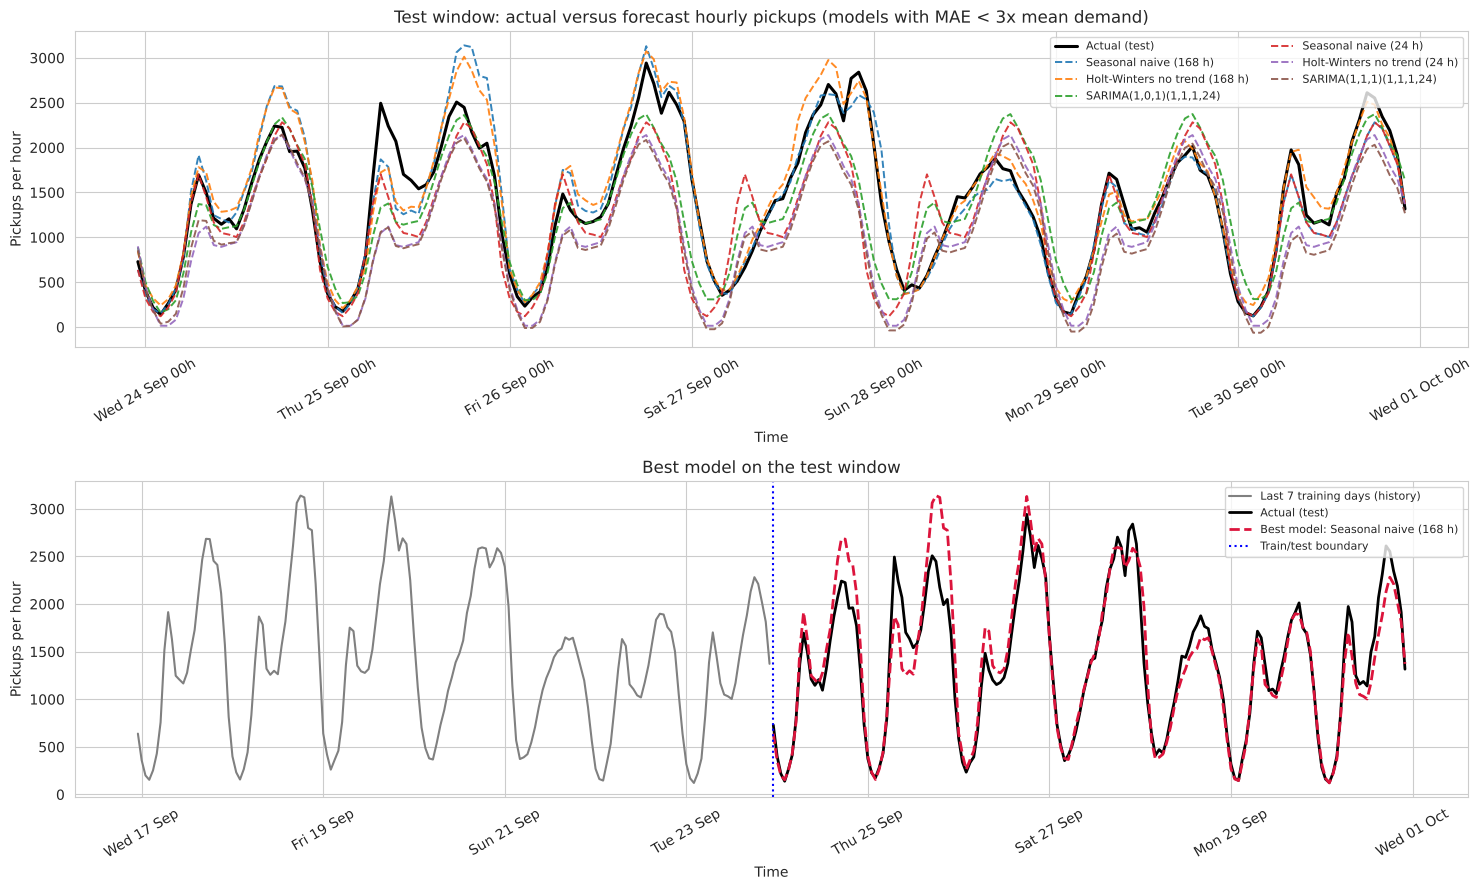

**Result.** The best model on the held-out week (23 Sep - 30 Sep 2014) is **Seasonal naive (168 h)**: MAE = 158.3, RMSE = 238.4 pickups per hour, MAPE = 10.55% (mean actual demand in the test window is 1,389 per hour). Relative to the 24-hour seasonal-naive baseline (MAE 317.9) its MAE is 50.2% lower. Its largest average absolute error occurs at hour 17:00. All models fitted without exceptions. Models whose forecast diverged (MAE above 3x mean demand, excluded from the top plot only): Holt-Winters add. trend (24 h) - typically because a fitted trend is extrapolated over a whole week. The two lowest-MAE models (Seasonal naive (168 h) and Holt-Winters no trend (168 h)) differ in MAE by only 6.0, so they are practically equivalent. Weekly models do well because the weekday/weekend pattern is part of the signal; daily-seasonal models cannot represent it. Because only one test week and one training month are available, small differences between models should not be over-interpreted.

In [15]:
ok_models = forecast_table[forecast_table["MAE"].notna()]
if ok_models.empty:
    raise RuntimeError("No forecasting model succeeded; see the Status column above.")
BEST_MODEL = ok_models.iloc[0]["Model"]
best_row = ok_models.iloc[0]
mean_test = float(test.mean())

fig, axes = plt.subplots(2, 1, figsize=(15, 9))
axes[0].plot(test.index, test.values, color="black", lw=2.2, label="Actual (test)")
good = [m_ for m_ in ok_models["Model"] if forecast_table.set_index("Model").loc[m_, "MAE"] < 3 * mean_test]   # drop wildly diverging models from the plot only
for m_ in good:
    axes[0].plot(test.index, forecasts[m_], ls="--", lw=1.4, alpha=0.9, label=m_)
axes[0].set_title("Test window: actual versus forecast hourly pickups (models with MAE < 3x mean demand)")
axes[0].set_ylabel("Pickups per hour"); axes[0].set_xlabel("Time"); axes[0].legend(fontsize=8, ncol=2)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b %Hh")); axes[0].tick_params(axis="x", rotation=30)

axes[1].plot(train.index[-168:], train.values[-168:], color="grey", label="Last 7 training days (history)")
axes[1].plot(test.index, test.values, color="black", lw=2, label="Actual (test)")
axes[1].plot(test.index, forecasts[BEST_MODEL], color="crimson", lw=2, ls="--", label=f"Best model: {BEST_MODEL}")
axes[1].axvline(test.index[0], color="blue", ls=":", label="Train/test boundary")
axes[1].set_title("Best model on the test window"); axes[1].set_ylabel("Pickups per hour"); axes[1].set_xlabel("Time"); axes[1].legend(fontsize=8)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b")); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

# error profile of the best model by hour of day
err_best = test.values - forecasts[BEST_MODEL]
worst_h = pd.Series(np.abs(err_best), index=test.index).groupby(test.index.hour).mean().idxmax()
sn24_mae = forecast_table.set_index("Model").loc["Seasonal naive (24 h)", "MAE"]
failed = forecast_table[forecast_table["MAE"].isna()]["Model"].tolist()
diverged = [m_ for m_ in ok_models["Model"] if forecast_table.set_index("Model").loc[m_, "MAE"] >= 3 * mean_test]
display(Markdown(
    f"**Result.** The best model on the held-out week ({test.index[0]:%d %b} - {test.index[-1]:%d %b %Y}) is **{BEST_MODEL}**: MAE = {best_row['MAE']:.1f}, RMSE = {best_row['RMSE']:.1f} pickups per hour, "
    f"MAPE = {best_row['MAPE (%)']:.2f}% (mean actual demand in the test window is {mean_test:,.0f} per hour). "
    f"Relative to the 24-hour seasonal-naive baseline (MAE {sn24_mae:.1f}) its MAE is {100*(1-best_row['MAE']/sn24_mae):.1f}% {'lower' if best_row['MAE'] < sn24_mae else 'higher'}. "
    f"Its largest average absolute error occurs at hour {int(worst_h):02d}:00. "
    + (f"Models that failed to fit: {', '.join(failed)}. " if failed else "All models fitted without exceptions. ")
    + (f"Models whose forecast diverged (MAE above 3x mean demand, excluded from the top plot only): {', '.join(diverged)} - typically because a fitted trend is extrapolated over a whole week. " if diverged else "")
    + (f"The two lowest-MAE models ({ok_models.iloc[0]['Model']} and {ok_models.iloc[1]['Model']}) differ in MAE by only {abs(ok_models.iloc[1]['MAE'] - ok_models.iloc[0]['MAE']):.1f}, so they are practically equivalent. " if len(ok_models) > 1 else "")
    + "Weekly models do well because the weekday/weekend pattern is part of the signal; daily-seasonal models cannot represent it. "
    "Because only one test week and one training month are available, small differences between models should not be over-interpreted."))

## 13. Future forecasting (next 24 hours)

The selected model is **re-fitted on the complete hourly series** (training + test), which is legitimate because the forecast period lies entirely after the last observation. The forecast covers the 24 hours after the last timestamp in the data. These values are **predictions, not observations**. Confidence intervals are shown only if the selected model provides them (SARIMA does). Otherwise, an *empirical error band* is shown, built from the 10th and 90th percentiles of the test-window forecast errors of the same model; this is an approximation, not a model-based confidence interval.

,Timestamp,Forecast (pickups/hour),Lower,Upper
0,2014-09-30 23:00:00,729,464,964
1,2014-10-01 00:00:00,403,138,638
2,2014-10-01 01:00:00,217,0,452
3,2014-10-01 02:00:00,139,0,374
4,2014-10-01 03:00:00,264,0,499
5,2014-10-01 04:00:00,415,150,650
6,2014-10-01 05:00:00,785,520,"1,020"
7,2014-10-01 06:00:00,"1,370","1,104","1,605"
8,2014-10-01 07:00:00,"1,695","1,430","1,930"
9,2014-10-01 08:00:00,"1,498","1,232","1,733"


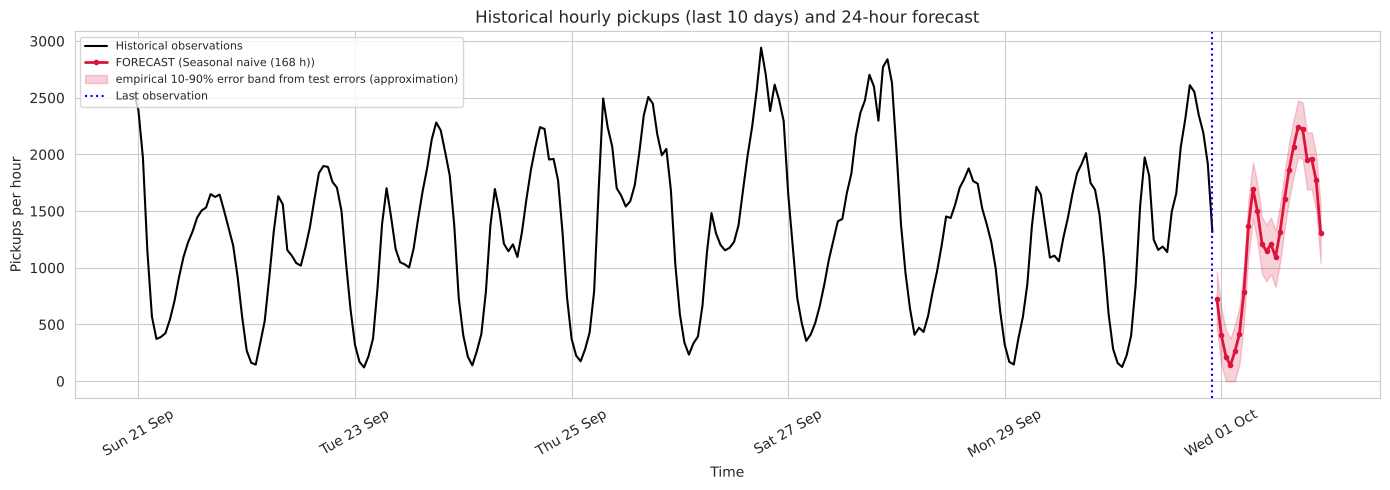

**Interpretation.** The forecast covers Tue 30 Sep 2014 23:00 to Wed 01 Oct 2014 22:00. The predicted peak is 2,241 pickups at 17:00 and the predicted minimum is 139 at 02:00; the forecast total for the 24 hours is 30,496 pickups. The selected model gives no model-based interval, so an approximate empirical band is shown. All of these are model predictions; no observations exist for this period in the dataset.

In [16]:
H = 24
future_index = pd.date_range(hourly.index.max() + pd.Timedelta(hours=1), periods=H, freq="h")
assert future_index.min() > hourly.index.max()

def refit_and_forecast(model_name, series, horizon):
    ci_ = None
    if model_name.startswith("Seasonal naive"):
        season = 24 if "24" in model_name else 168
        mean_ = seasonal_naive(series, season, horizon)
    elif model_name.startswith("Holt-Winters"):
        season = 24 if "(24" in model_name else 168
        trend = "add" if "add. trend" in model_name else None
        mean_ = np.asarray(ExponentialSmoothing(series, trend=trend, seasonal="add", seasonal_periods=season).fit().forecast(horizon))
    elif model_name.startswith("SARIMA"):
        order = (1, 1, 1) if model_name.startswith("SARIMA(1,1,1)") else (1, 0, 1)
        res = SARIMAX(series, order=order, seasonal_order=(1, 1, 1, 24)).fit(disp=False, maxiter=200)
        fc = res.get_forecast(horizon)
        mean_, ci_ = np.asarray(fc.predicted_mean), np.asarray(fc.conf_int(alpha=0.05))
    else:
        raise ValueError(model_name)
    return mean_, ci_

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=(ConvergenceWarning, SMConvergenceWarning))
    future_mean, future_ci = refit_and_forecast(BEST_MODEL, hourly, H)
future_mean = np.clip(future_mean, 0, None)

if future_ci is not None:
    lower, upper, band_label = np.clip(future_ci[:, 0], 0, None), future_ci[:, 1], "95% confidence interval (model-based)"
else:
    q10, q90 = np.percentile(err_best, [10, 90])
    lower, upper = np.clip(future_mean + q10, 0, None), future_mean + q90
    band_label = "empirical 10-90% error band from test errors (approximation)"

future_df = pd.DataFrame({"Timestamp": future_index, "Forecast (pickups/hour)": future_mean, "Lower": lower, "Upper": upper}).set_index("Timestamp")
display(fmt_table(future_df.reset_index(), {"Forecast (pickups/hour)": "{:,.0f}", "Lower": "{:,.0f}", "Upper": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(14, 5))
hist_view = hourly.iloc[-24 * 10:]
ax.plot(hist_view.index, hist_view.values, color="black", lw=1.5, label="Historical observations")
ax.plot(future_index, future_mean, color="crimson", lw=2, marker="o", ms=3, label=f"FORECAST ({BEST_MODEL})")
ax.fill_between(future_index, lower, upper, color="crimson", alpha=0.2, label=band_label)
ax.axvline(hourly.index.max(), color="blue", ls=":", label="Last observation")
ax.set_title("Historical hourly pickups (last 10 days) and 24-hour forecast"); ax.set_xlabel("Time"); ax.set_ylabel("Pickups per hour")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b")); ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fpeak = future_df["Forecast (pickups/hour)"].idxmax(); ftrough = future_df["Forecast (pickups/hour)"].idxmin()
display(Markdown(
    f"**Interpretation.** The forecast covers {future_index[0]:%a %d %b %Y %H:%M} to {future_index[-1]:%a %d %b %Y %H:%M}. "
    f"The predicted peak is {future_df.loc[fpeak, 'Forecast (pickups/hour)']:,.0f} pickups at {fpeak:%H:%M} and the predicted minimum is {future_df.loc[ftrough, 'Forecast (pickups/hour)']:,.0f} at {ftrough:%H:%M}; "
    f"the forecast total for the 24 hours is {future_mean.sum():,.0f} pickups. "
    + ("The selected model supplies a model-based 95% interval. " if future_ci is not None else "The selected model gives no model-based interval, so an approximate empirical band is shown. ")
    + "All of these are model predictions; no observations exist for this period in the dataset."))

## 14. Conclusions and limitations

The text below is generated from the computed results above (no figures are typed by hand).

In [17]:
c_big = centroids.sort_values("Pickups", ascending=False)
cluster_lines = "\n".join(
    f"  - Cluster {int(r['Cluster'])}: {r['Pickups']:,.0f} pickups ({r['Share (%)']:.1f}%), centre ({r['Centroid lat']:.4f}, {r['Centroid lon']:.4f}), {r['Description']}"
    for _, r in centroids.iterrows())
peak_lines = "; ".join(f"cluster {int(r['Cluster'])} at {r['Peak hour']}" for _, r in peak_table.iterrows())
weekend_above = [str(c) for c in wk.index if wk.loc[c, "Weekend / weekday ratio"] > city_ratio]
cleaning_text = "; ".join(f"{r.Step}: {r.Removed:,d}" for r in cleaning_summary.itertuples())
sil_ok, db_ok, ch_ok = kfin["Silhouette"], kfin["Davies-Bouldin"], kfin["Calinski-Harabasz"]

conclusions = f'''
**Data cleaning.** The raw file has {n_raw:,d} records; after cleaning {n_clean:,d} remain ({100*n_clean/n_raw:.2f}%), covering {date_start:%d %b %Y %H:%M} to {date_end:%d %b %Y %H:%M} ({df["Date"].nunique()} days). Records removed by step - {cleaning_text}. 
Exact duplicates ({n_duplicates_removed:,d}, i.e. {100*n_duplicates_removed/n_raw:.2f}% of raw data) may include genuinely separate pickups recorded in the same minute at the same rounded location, so absolute demand is probably slightly understated.

**Geographic findings.** Pickups are strongly concentrated: {100*share_core:.1f}% lie in a small central rectangle (latitude 40.70-40.80, longitude -74.02 to -73.95). The data were projected to kilometres (R cos(lat0) scaling of longitude) before clustering, with a round-trip error of {roundtrip_err_deg:.1e} degrees.

**Clustering.** MiniBatchKMeans with **k = {K_FINAL}** was selected as the k in {K_LO}-{K_HI} with the highest equal-weight composite of normalised Silhouette, Davies-Bouldin and Calinski-Harabasz scores (the restriction is a judgement: k = 2 gives only a trivial core/periphery split and k > {K_HI} gives too many zones to interpret; unrestricted, the composite would favour k = {K_UNRESTRICTED}; the best k within the range was {K_FINAL} in {n_agree} of 5 resampling checks, but {K_FINAL} is the upper edge of the candidate range and the indices keep improving beyond it, so it is a working choice and not a proven optimum). At k = {K_FINAL} on the 50,000-point sample: Silhouette = {sil_ok:.3f}, Davies-Bouldin = {db_ok:.3f}, Calinski-Harabasz = {ch_ok:,.0f}. The final MiniBatchKMeans model fitted on all data scores {final_metrics['Silhouette']:.3f}, {final_metrics['Davies-Bouldin']:.3f} and {final_metrics['Calinski-Harabasz']:,.0f} on the same sample (slightly lower than the exact K-Means sweep because it is a different fit: mini-batch updates on all points versus exact K-Means on the sample). The clusters are:
{cluster_lines}

**DBSCAN comparison.** With eps = {EPS_PRIMARY_KM} km and min_samples = {DB_MIN_SAMPLES} on a {DB_SAMPLE_N:,d}-point sample, DBSCAN found {n_db_clusters} clusters and {100*n_db_noise/DB_SAMPLE_N:.1f}% noise, with {largest_share:.1f}% of clustered points in its largest cluster. It is sensitive to eps and answers a different question from K-Means, so it is a contrast and not a validation.

**Temporal patterns.** City-wide pickups peak at {peak_hour:02d}:00 and are lowest at {trough_hour:02d}:00. Cluster peak hours: {peak_lines}. The city-wide weekend/weekday per-day ratio is {city_ratio:.2f}; clusters with a ratio above it: {', '.join(weekend_above) if weekend_above else 'none'}. The busiest date was {top_date:%d %b} ({date_counts.max():,d} pickups) and the quietest {low_date:%d %b} ({date_counts.min():,d}).

**Forecasting.** On the final {TEST_HOURS} hours (held out), the best model was **{BEST_MODEL}** with MAE = {best_row['MAE']:.1f}, RMSE = {best_row['RMSE']:.1f} and MAPE = {best_row['MAPE (%)']:.2f}% (zero-actual hours excluded from MAPE: {int(best_row['Zero-actual hours excluded'])}). The 24-hour forecast from {future_index[0]:%d %b %H:%M} predicts a peak of {future_df['Forecast (pickups/hour)'].max():,.0f} pickups per hour at {fpeak:%H:%M} and about {future_mean.sum():,.0f} pickups in total; {'a model-based 95% interval is available' if future_ci is not None else 'only an approximate empirical error band is available'}.

**Limitations.**
- Only one month is observed: monthly or yearly seasonality, holidays, weather and events cannot be separated from ordinary variation, and each weekday occurs only 4-5 times.
- K-Means assumes compact, similarly sized clusters and Euclidean geometry after a local projection, and every point (including distant ones) is forced into a cluster. The choice of k rests on a documented rule and a 1% admissibility threshold, not on a unique optimum. Metrics were computed on samples.
- DBSCAN results depend heavily on eps and min_samples and were obtained on a sample.
- Forecasting uses a single train/test split with one forecast origin, models were compared on the same test week (optimistic for the winner), the training window is only about three weeks, and no external regressors are used. A weekly-period SARIMA (period 168) was not included because it is very memory-intensive (it exhausted memory in the environment used to build this notebook), and the extra uncertainty of the final refit is not captured by the empirical band when no model interval exists.
- Removing exact duplicates may under-count real simultaneous pickups; pickup-only data has no drop-off or fare information.

**Recommendations for future work.** Use several months of data to model monthly seasonality and holidays; add external regressors (weather, events) via SARIMAX or gradient-boosting models; use rolling-origin cross-validation for forecasting; try Gaussian mixture or HDBSCAN models for irregular spatial shapes; and forecast each cluster separately to support zone-level supply planning.
'''
display(Markdown(conclusions))


**Data cleaning.** The raw file has 1,028,136 records; after cleaning 1,003,491 remain (97.60%), covering 01 Sep 2014 00:00 to 30 Sep 2014 22:59 (30 days). Records removed by step - Drop rows with missing values/timestamps: 0; Drop impossible coordinates: 0; Drop exact duplicates (all 4 fields): 24,037; Drop points outside NYC-area bounding box: 608. 
Exact duplicates (24,037, i.e. 2.34% of raw data) may include genuinely separate pickups recorded in the same minute at the same rounded location, so absolute demand is probably slightly understated.

**Geographic findings.** Pickups are strongly concentrated: 74.7% lie in a small central rectangle (latitude 40.70-40.80, longitude -74.02 to -73.95). The data were projected to kilometres (R cos(lat0) scaling of longitude) before clustering, with a round-trip error of 0.0e+00 degrees.

**Clustering.** MiniBatchKMeans with **k = 8** was selected as the k in 3-8 with the highest equal-weight composite of normalised Silhouette, Davies-Bouldin and Calinski-Harabasz scores (the restriction is a judgement: k = 2 gives only a trivial core/periphery split and k > 8 gives too many zones to interpret; unrestricted, the composite would favour k = 10; the best k within the range was 8 in 5 of 5 resampling checks, but 8 is the upper edge of the candidate range and the indices keep improving beyond it, so it is a working choice and not a proven optimum). At k = 8 on the 50,000-point sample: Silhouette = 0.458, Davies-Bouldin = 0.652, Calinski-Harabasz = 33,436. The final MiniBatchKMeans model fitted on all data scores 0.406, 0.700 and 32,411 on the same sample (slightly lower than the exact K-Means sweep because it is a different fit: mini-batch updates on all points versus exact K-Means on the sample). The clusters are:
  - Cluster 0: 351,285 pickups (35.0%), centre (40.7262, -73.9957), within 1.1 km of Union Square
  - Cluster 1: 316,439 pickups (31.5%), centre (40.7551, -73.9827), within 0.4 km of Times Square
  - Cluster 2: 133,851 pickups (13.3%), centre (40.7811, -73.9605), nearest reference: Central Park (south end) (2.1 km away)
  - Cluster 3: 106,303 pickups (10.6%), centre (40.6800, -73.9655), nearest reference: Downtown Brooklyn (2.5 km away)
  - Cluster 4: 40,129 pickups (4.0%), centre (40.7599, -73.8650), nearest reference: LaGuardia Airport (2.0 km away)
  - Cluster 5: 29,595 pickups (2.9%), centre (40.6598, -73.7662), nearest reference: JFK Airport (2.3 km away)
  - Cluster 6: 16,064 pickups (1.6%), centre (40.8765, -73.9008), nearest reference: Columbia University (9.3 km away)
  - Cluster 7: 9,825 pickups (1.0%), centre (40.6996, -74.1984), nearest reference: Newark Airport (2.3 km away)

**DBSCAN comparison.** With eps = 0.3 km and min_samples = 20 on a 30,000-point sample, DBSCAN found 27 clusters and 9.0% noise, with 80.2% of clustered points in its largest cluster. It is sensitive to eps and answers a different question from K-Means, so it is a contrast and not a validation.

**Temporal patterns.** City-wide pickups peak at 18:00 and are lowest at 02:00. Cluster peak hours: cluster 0 at 18:00; cluster 1 at 17:00; cluster 2 at 07:00; cluster 3 at 21:00; cluster 4 at 20:00; cluster 5 at 14:00; cluster 6 at 21:00; cluster 7 at 15:00. The city-wide weekend/weekday per-day ratio is 1.02; clusters with a ratio above it: 0, 3, 4, 5, 6. The busiest date was 13 Sep (42,148 pickups) and the quietest 01 Sep (19,552).

**Forecasting.** On the final 168 hours (held out), the best model was **Seasonal naive (168 h)** with MAE = 158.3, RMSE = 238.4 and MAPE = 10.55% (zero-actual hours excluded from MAPE: 0). The 24-hour forecast from 30 Sep 23:00 predicts a peak of 2,241 pickups per hour at 17:00 and about 30,496 pickups in total; only an approximate empirical error band is available.

**Limitations.**
- Only one month is observed: monthly or yearly seasonality, holidays, weather and events cannot be separated from ordinary variation, and each weekday occurs only 4-5 times.
- K-Means assumes compact, similarly sized clusters and Euclidean geometry after a local projection, and every point (including distant ones) is forced into a cluster. The choice of k rests on a documented rule and a 1% admissibility threshold, not on a unique optimum. Metrics were computed on samples.
- DBSCAN results depend heavily on eps and min_samples and were obtained on a sample.
- Forecasting uses a single train/test split with one forecast origin, models were compared on the same test week (optimistic for the winner), the training window is only about three weeks, and no external regressors are used. A weekly-period SARIMA (period 168) was not included because it is very memory-intensive (it exhausted memory in the environment used to build this notebook), and the extra uncertainty of the final refit is not captured by the empirical band when no model interval exists.
- Removing exact duplicates may under-count real simultaneous pickups; pickup-only data has no drop-off or fare information.

**Recommendations for future work.** Use several months of data to model monthly seasonality and holidays; add external regressors (weather, events) via SARIMAX or gradient-boosting models; use rolling-origin cross-validation for forecasting; try Gaussian mixture or HDBSCAN models for irregular spatial shapes; and forecast each cluster separately to support zone-level supply planning.


## 15. Final verification

In [18]:
checks = []
def check(description, condition):
    ok = bool(condition)
    checks.append((description, ok))

finite = lambda v: bool(np.isfinite(v))
check("Cleaned dataset is not empty", len(df) > 0)
check("All required columns exist in cleaned data", all(c in df.columns for c in REQUIRED_COLUMNS))
check("All timestamps are parsed (datetime dtype, no NaT)", pd.api.types.is_datetime64_any_dtype(df["Date/Time"]) and df["Date/Time"].notna().all())
check("Derived time features exist and are valid (Hour 0-23, Weekday 0-6)", df["Hour"].between(0, 23).all() and df["Weekday"].between(0, 6).all())
check("No missing values in cleaned analysis columns", df[["Lat", "Lon", "x_km", "y_km", "Cluster"]].notna().all().all())
check("No duplicate records remain", not df.duplicated(subset=REQUIRED_COLUMNS).any())
check("All points lie inside the bounding box", df["Lat"].between(LAT_MIN, LAT_MAX).all() and df["Lon"].between(LON_MIN, LON_MAX).all())
check("Coordinate transformation round-trip error < 1e-9 degrees", roundtrip_err_deg < 1e-9)
check("Cluster labels exist for every record", "Cluster" in df.columns and df["Cluster"].notna().all())
check("Number of distinct cluster labels equals the selected k", df["Cluster"].nunique() == K_FINAL)
check("Cluster labels are 0..k-1", sorted(df["Cluster"].unique().tolist()) == list(range(K_FINAL)))
check("Cluster summary has k rows and valid values", len(centroids) == K_FINAL and centroids[["Centroid lat", "Centroid lon", "Pickups"]].notna().all().all() and (centroids["Pickups"] > 0).all())
check("Cluster sizes sum to the cleaned record count", int(centroids["Pickups"].sum()) == len(df))
check("Centroids lie inside the bounding box", centroids["Centroid lat"].between(LAT_MIN, LAT_MAX).all() and centroids["Centroid lon"].between(LON_MIN, LON_MAX).all())
check("k sweep covers k = 2..10 with finite metrics", len(k_results) == 9 and np.isfinite(k_results[["Inertia", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "Composite (all k=2-10)"]].to_numpy()).all())
check("Final clustering metrics are finite", all(finite(v) for v in final_metrics.values()))
check("Selected k comes from the candidate set and has the highest candidate composite", K_FINAL in k_results.loc[k_results["Candidate"], "k"].tolist() and np.isclose(kfin["Composite (candidates)"], k_results["Composite (candidates)"].max()))
check("DBSCAN result is available and consistent", len(db_labels) == DB_SAMPLE_N and n_db_clusters >= 0 and 0 <= n_db_noise <= DB_SAMPLE_N)
check("Cluster-hour table has k rows x 24 columns and sums to the record count", pivot_hour.shape == (K_FINAL, 24) and int(pivot_hour.values.sum()) == len(df))
check("Normalised hourly rows sum to 100%", np.allclose(pivot_hour_share.sum(axis=1), 100))
check("Cluster-date table sums to the record count", int(pivot_date.values.sum()) == len(df))
check("Hourly series is regular, chronological and preserves zero hours", hourly.index.is_monotonic_increasing and (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all() and int(hourly.sum()) == len(df))
check("Training period precedes test period (no leakage)", train.index.max() < test.index.min() and len(train) + len(test) == len(hourly))
check("At least one forecasting model succeeded", len(ok_models) >= 1)
check("Forecast metrics are finite for successful models", np.isfinite(ok_models[["MAE", "RMSE", "MAPE (%)"]].to_numpy()).all())
check("Best model has the lowest test MAE", np.isclose(best_row["MAE"], ok_models["MAE"].min()))
check("Future forecast has exactly 24 periods", len(future_df) == 24)
check("Future forecast is strictly after the last observation", future_df.index.min() > hourly.index.max())
check("Future forecast values are finite and non-negative", np.isfinite(future_df.to_numpy()).all() and (future_df["Forecast (pickups/hour)"] >= 0).all())
check("Conclusions text is generated, with no placeholders or NaN values", len(conclusions) > 500 and "[insert" not in conclusions and "nan" not in conclusions.lower().replace("finan", ""))

print("=" * 78)
print("FINAL VALIDATION REPORT")
print("=" * 78)
for desc, ok in checks:
    print(f"[{'PASS' if ok else 'FAIL'}] {desc}")
n_pass = sum(ok for _, ok in checks)
print("-" * 78)
print(f"{n_pass} of {len(checks)} checks passed.")
print(f"Records: {n_clean:,d} | k = {K_FINAL} | best forecast model: {BEST_MODEL} (test MAE {best_row['MAE']:.1f})")
if n_pass != len(checks):
    raise AssertionError("Validation failed: " + "; ".join(d for d, ok in checks if not ok))
print("ALL CHECKS PASSED.")

FINAL VALIDATION REPORT
[PASS] Cleaned dataset is not empty
[PASS] All required columns exist in cleaned data
[PASS] All timestamps are parsed (datetime dtype, no NaT)
[PASS] Derived time features exist and are valid (Hour 0-23, Weekday 0-6)
[PASS] No missing values in cleaned analysis columns
[PASS] No duplicate records remain
[PASS] All points lie inside the bounding box
[PASS] Coordinate transformation round-trip error < 1e-9 degrees
[PASS] Cluster labels exist for every record
[PASS] Number of distinct cluster labels equals the selected k
[PASS] Cluster labels are 0..k-1
[PASS] Cluster summary has k rows and valid values
[PASS] Cluster sizes sum to the cleaned record count
[PASS] Centroids lie inside the bounding box
[PASS] k sweep covers k = 2..10 with finite metrics
[PASS] Final clustering metrics are finite
[PASS] Selected k comes from the candidate set and has the highest candidate composite
[PASS] DBSCAN result is available and consistent
[PASS] Cluster-hour table has k rows x